In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-01
# SECTION 1: POTHRGBD METRIC-SCALE EVIDENCE AUDIT
# Version: 1.0
#
# READ-ONLY SOURCE DATA
# NO ASSUMED PHYSICAL UNITS
# NO TRAINING OR LABEL GENERATION
# ============================================================

from google.colab import drive
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import hashlib
import json
import csv

# ------------------------------------------------------------
# 1. CONNECT GOOGLE DRIVE
# ------------------------------------------------------------

if not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive")

DRIVE = Path("/content/drive/MyDrive")

DATA = DRIVE / "manushi_research_data"

PROJECT = (
    DRIVE / "crdl_experiments"
    / "component3_fresh_v1"
)

AUDITS = PROJECT / "02_dataset_audits"

DEPTH_ROOT = (
    DATA / "pothrgbd"
    / "PData-main" / "depths"
)

POTHRGBD_ROOT = DEPTH_ROOT.parent

# ------------------------------------------------------------
# 2. VERIFY C3-00 HANDOFF
# ------------------------------------------------------------

C300_RUN = AUDITS / (
    "C3-00_section07_20261020T045501_723203Z"
)

handoff = C300_RUN / "readiness_report.json"
checksum_file = C300_RUN / "checksums.sha256"

assert handoff.is_file(), "C3-00 handoff missing"
assert checksum_file.is_file(), "C3-00 checksums missing"
assert DEPTH_ROOT.is_dir(), "PothRGBD depth folder missing"

verified_files = []

for line in checksum_file.read_text(
    encoding="utf-8"
).splitlines():

    if not line.strip():
        continue

    expected, name = line.split(None, 1)
    name = name.strip()

    if Path(name).name != name:
        raise ValueError("Unsafe checksum entry")

    path = C300_RUN / name

    actual = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    if actual != expected:
        raise RuntimeError(
            f"C3-00 integrity failure: {name}"
        )

    verified_files.append(name)

previous = json.loads(
    handoff.read_text(encoding="utf-8")
)

assert previous["milestone"] == "C3-00"
assert previous["section"] == 7
assert (
    previous["physical_depth_training_authorized"]
    is False
)

print("C3-00 handoff integrity: PASS")
print("Verified:", verified_files)

# ------------------------------------------------------------
# 3. INSPECT SELECTED ORIGINAL DEPTH ARRAYS
# ------------------------------------------------------------

# Known development examples from C3-00.
# No test or protected evaluation data.
SAMPLE_IDS = [
    "20250227_135438",
    "20250227_135652",
    "20250227_140407",
]

samples = []

print("\nPOTHRGBD RAW DEPTH INSPECTION")
print("-" * 65)

for sample_id in SAMPLE_IDS:

    path = DEPTH_ROOT / f"{sample_id}_depth.npy"

    assert path.is_file(), f"Missing: {path.name}"
    assert path.stat().st_size < 10_000_000

    depth = np.load(
        path,
        allow_pickle=False
    )

    assert depth.shape == (480, 640)
    assert depth.dtype == np.uint16

    valid = depth > 0
    values = depth[valid].astype(np.float64)

    if not values.size:
        raise ValueError(
            f"No nonzero depth values in {sample_id}"
        )

    record = {
        "sample_id": sample_id,
        "filename": path.name,
        "shape": list(depth.shape),
        "dtype": str(depth.dtype),
        "valid_fraction": float(valid.mean()),
        "raw_median": float(np.median(values)),
        "raw_p01": float(np.percentile(values, 1)),
        "raw_p99": float(np.percentile(values, 99)),
        "raw_p999": float(np.percentile(values, 99.9)),
        "raw_max": float(values.max()),
        "source_sha256": hashlib.sha256(
            path.read_bytes()
        ).hexdigest(),
        "units": "RAW_SENSOR_UNITS_UNVERIFIED",
    }

    samples.append(record)

    print(
        sample_id,
        "| median:", record["raw_median"],
        "| p99:", round(record["raw_p99"], 2),
        "| max:", record["raw_max"]
    )

# ------------------------------------------------------------
# 4. SEARCH FOR CAPTURE-SPECIFIC METADATA FILES
# ------------------------------------------------------------

# A bounded search in the two relevant parent folders.
# Does not traverse the 1000 image/depth files.

METADATA_SUFFIXES = {
    ".json", ".yaml", ".yml", ".txt",
    ".md", ".csv", ".ini", ".xml", ".bag"
}

metadata_candidates = []

for folder in [
    POTHRGBD_ROOT,
    POTHRGBD_ROOT.parent
]:

    for path in folder.iterdir():

        if (
            path.is_file()
            and not path.is_symlink()
            and path.suffix.lower() in METADATA_SUFFIXES
        ):

            metadata_candidates.append({
                "relative_path": str(
                    path.relative_to(DATA)
                ),
                "size_bytes": path.stat().st_size,
            })

print("\nCAPTURE METADATA CANDIDATES")
print("-" * 65)

if metadata_candidates:
    for item in metadata_candidates:
        print(item["relative_path"])
else:
    print(
        "No metadata candidates in scanned root folders."
    )

# ------------------------------------------------------------
# 5. DEFINE SCIENTIFIC CALIBRATION REQUIREMENTS
# ------------------------------------------------------------

required_evidence = {
    "sensor_model": {
        "reported_model": "Intel RealSense D415",
        "status": "REPORTED_NOT_CAPTURE_VERIFIED",
    },

    "depth_scale_m_per_unit": {
        "manufacturer_default_hypothesis": 0.001,
        "actual_capture_value": None,
        "status": "UNVERIFIED",
    },

    "camera_intrinsics": {
        "fx": None,
        "fy": None,
        "cx": None,
        "cy": None,
        "status": "NOT_YET_VERIFIED",
    },

    "rgb_depth_registration": {
        "status": "VISUALLY_PLAUSIBLE_NOT_CERTIFIED",
    },

    "independent_physical_validation": {
        "status": "NOT_YET_AVAILABLE",
    },
}

# ------------------------------------------------------------
# 6. SAVE VERSIONED EVIDENCE REPORT
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = AUDITS / f"C3-01_section01_{stamp}"

OUT.mkdir(exist_ok=False)

report = {
    "component": "CRDL_Component_3",
    "milestone": "C3-01",
    "section": 1,
    "created_utc": stamp,
    "source_dataset": "PothRGBD",
    "previous_handoff_verified": True,
    "raw_depth_samples": samples,
    "metadata_candidates": metadata_candidates,
    "required_calibration": required_evidence,
    "physical_unit_status": "UNVERIFIED",
    "road_relative_labels_created": False,
    "metric_training_authorized": False,
    "note": (
        "Default RealSense depth scale is a hypothesis. "
        "Raw sensor values must not be treated as "
        "certified metres without source-specific evidence."
    ),
}

json_path = OUT / "pothrgbd_scale_evidence.json"

json_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

csv_path = OUT / "raw_depth_profiles.csv"

with csv_path.open(
    "w", newline="", encoding="utf-8"
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "sample",
        "valid_fraction",
        "raw_median",
        "raw_p01",
        "raw_p99",
        "raw_p999",
        "raw_max",
        "units",
    ])

    for s in samples:
        writer.writerow([
            s["sample_id"],
            s["valid_fraction"],
            s["raw_median"],
            s["raw_p01"],
            s["raw_p99"],
            s["raw_p999"],
            s["raw_max"],
            s["units"],
        ])

# ------------------------------------------------------------
# 7. GENERATE CHECKSUMS
# ------------------------------------------------------------

checksum_lines = []

for path in [json_path, csv_path]:

    digest = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    checksum_lines.append(
        f"{digest}  {path.name}"
    )

(OUT / "checksums.sha256").write_text(
    "\n".join(checksum_lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 8. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-01 SECTION 1 — RESULTS")
print("=" * 65)

print("C3-00 handoff: VERIFIED")
print("Raw depth probes:", len(samples))
print("Depth format: uint16")
print(
    "Metadata candidates:",
    len(metadata_candidates)
)

print("Manufacturer default scale: 0.001 m/unit")
print("Actual dataset scale: NOT CERTIFIED")
print("Camera intrinsics: NOT CERTIFIED")
print("Road-relative metric labels: NOT GENERATED")
print("Physical depth training: NOT AUTHORIZED")
print("\nSaved report:", OUT)
print("=" * 65)


Mounted at /content/drive
C3-00 handoff integrity: PASS
Verified: ['readiness_report.json', 'dataset_readiness.csv']

POTHRGBD RAW DEPTH INSPECTION
-----------------------------------------------------------------
20250227_135438 | median: 1169.0 | p99: 1419.0 | max: 1470.0
20250227_135652 | median: 1335.0 | p99: 1611.0 | max: 12583.0
20250227_140407 | median: 1055.0 | p99: 1512.0 | max: 1621.0

CAPTURE METADATA CANDIDATES
-----------------------------------------------------------------
No metadata candidates in scanned root folders.

C3-01 SECTION 1 — RESULTS
C3-00 handoff: VERIFIED
Raw depth probes: 3
Depth format: uint16
Metadata candidates: 0
Manufacturer default scale: 0.001 m/unit
Actual dataset scale: NOT CERTIFIED
Camera intrinsics: NOT CERTIFIED
Road-relative metric labels: NOT GENERATED
Physical depth training: NOT AUTHORIZED

Saved report: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-01_section01_20261020T045938_052906Z


CRDL C3-01 — FAN STEREO GEOMETRY
Disparity shape: (1028, 1730)
3D points shape: (1028, 1730, 3)
Disparity dtype: float64
Point-cloud dtype: float64

GEOMETRY VALIDITY
Valid pixel fraction: 0.9906
Sampled valid points: 27668

RAW COORDINATES — UNITS UNVERIFIED
X: median=69.7208, p01=-456.1308, p99=588.7161
Y: median=-25.9940, p01=-412.7877, p99=161.7727
Z: median=665.9148, p01=489.9036, p99=1039.7674

STEREO CONSISTENCY DIAGNOSTIC
Correlation (disparity, 1/|Z|): 0.9999999999999994
Median disparity × |Z|: 165033.65829406527
Z-positive fraction: 1.0


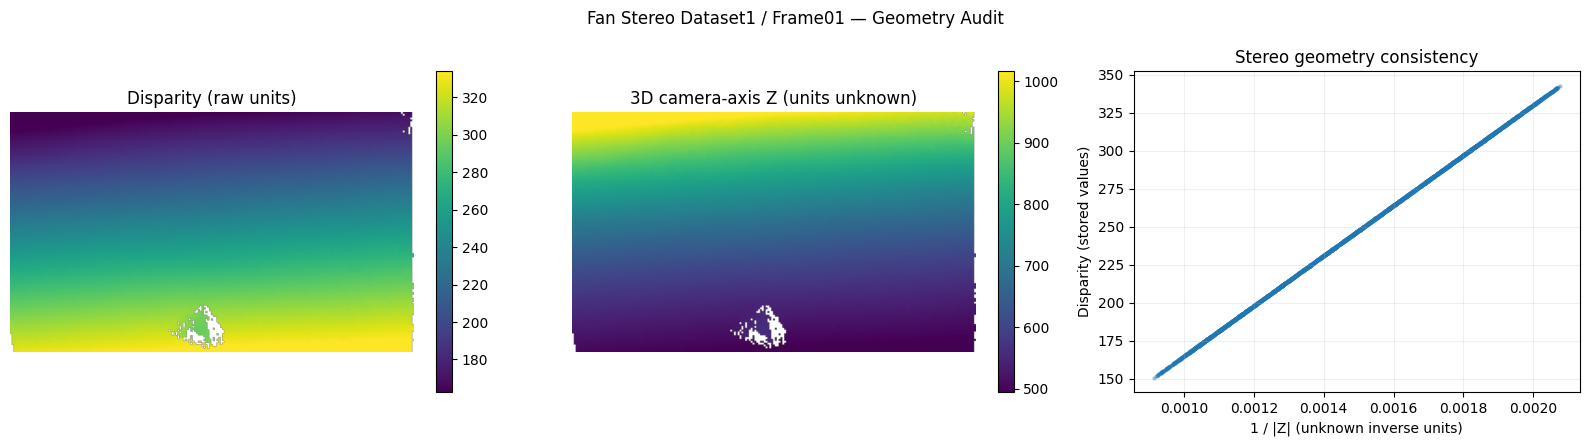


C3-01 SECTION 2 — SUMMARY
Geometry array validation: PASS
Valid point fraction: 0.9906
Sampled valid points: 27668
Inverse-depth correlation: 0.9999999999999994
Median disparity × |Z|: 165033.65829406527
Coordinate units: NOT CERTIFIED
Camera calibration: NOT CERTIFIED
Metric training authorized: NO
Saved report: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-01_section02_20261020T050231_518844Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-01
# SECTION 2: FAN STEREO 3D GEOMETRY VERIFICATION
# Version: 1.0
# DEVELOPMENT DATA ONLY | NO METRIC UNIT ASSUMPTIONS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from scipy.io import loadmat
import numpy as np
import matplotlib.pyplot as plt
import json
import hashlib

# ------------------------------------------------------------
# 1. DEFINE SOURCE AND OUTPUT PATHS
# ------------------------------------------------------------

DRIVE = Path("/content/drive/MyDrive")

BASE = (
    DRIVE / "manushi_research_data"
    / "fan_stereo_pothole"
    / "stereo_pothole_datasets-master"
    / "dataset1"
)

AUDIT_ROOT = (
    DRIVE / "crdl_experiments"
    / "component3_fresh_v1"
    / "02_dataset_audits"
)

DISP_FILE = BASE / "disp" / "01.mat"
XYZ_FILE = BASE / "ptcloud" / "01.mat"

assert DISP_FILE.is_file(), "Missing disparity file"
assert XYZ_FILE.is_file(), "Missing point cloud file"
assert AUDIT_ROOT.is_dir()

# ------------------------------------------------------------
# 2. LOAD THE ORIGINAL SCIENTIFIC ARRAYS
# ------------------------------------------------------------

disp_data = loadmat(
    str(DISP_FILE),
    variable_names=["disp"]
)

xyz_data = loadmat(
    str(XYZ_FILE),
    variable_names=["xyzPoints"]
)

if "disp" not in disp_data:
    raise KeyError("MAT variable 'disp' missing")

if "xyzPoints" not in xyz_data:
    raise KeyError("MAT variable 'xyzPoints' missing")

disp = np.asarray(
    disp_data["disp"], dtype=np.float64
)

xyz = np.asarray(
    xyz_data["xyzPoints"], dtype=np.float64
)

if disp.ndim != 2:
    raise ValueError("Disparity must be 2D")

if xyz.shape != (*disp.shape, 3):
    raise ValueError(
        f"Unexpected shapes: disp={disp.shape}, "
        f"xyz={xyz.shape}"
    )

print("=" * 65)
print("CRDL C3-01 — FAN STEREO GEOMETRY")
print("=" * 65)

print("Disparity shape:", disp.shape)
print("3D points shape:", xyz.shape)
print("Disparity dtype:", disp.dtype)
print("Point-cloud dtype:", xyz.dtype)

# ------------------------------------------------------------
# 3. IDENTIFY FINITE, GEOMETRICALLY USABLE POINTS
# ------------------------------------------------------------

X = xyz[:, :, 0]
Y = xyz[:, :, 1]
Z = xyz[:, :, 2]

# Only positive disparity and finite nonzero 3D
# coordinates participate in this diagnostic.
valid = (
    np.isfinite(disp)
    & np.isfinite(xyz).all(axis=2)
    & (disp > 0)
    & (np.abs(Z) > 1e-9)
    & np.any(np.abs(xyz) > 1e-9, axis=2)
)

valid_fraction = float(np.mean(valid))

# Subsample uniformly for bounded analysis.
STEP = 8

sample_valid = valid[::STEP, ::STEP]
sample_disp = disp[::STEP, ::STEP]
sample_z = Z[::STEP, ::STEP]

d = sample_disp[sample_valid]
z = sample_z[sample_valid]

if len(d) < 200:
    raise RuntimeError(
        "Insufficient valid points. Review Fan encoding."
    )

print("\nGEOMETRY VALIDITY")
print("Valid pixel fraction:", round(valid_fraction, 4))
print("Sampled valid points:", len(d))

# ------------------------------------------------------------
# 4. ANALYZE RAW 3D COORDINATE DISTRIBUTION
# ------------------------------------------------------------

def numeric_stats(values):
    values = np.asarray(values, dtype=np.float64)
    values = values[np.isfinite(values)]

    if not values.size:
        return {"count": 0}

    return {
        "count": int(values.size),
        "min": float(np.min(values)),
        "p01": float(np.percentile(values, 1)),
        "median": float(np.median(values)),
        "p99": float(np.percentile(values, 99)),
        "max": float(np.max(values)),
    }

coordinates = {}

for idx, name in enumerate(["X", "Y", "Z"]):
    component = xyz[:, :, idx][::STEP, ::STEP]
    coordinates[name] = numeric_stats(
        component[sample_valid]
    )

disparity_stats = numeric_stats(d)

print("\nRAW COORDINATES — UNITS UNVERIFIED")

for name, stats in coordinates.items():
    print(
        f"{name}: median={stats['median']:.4f}, "
        f"p01={stats['p01']:.4f}, "
        f"p99={stats['p99']:.4f}"
    )

# ------------------------------------------------------------
# 5. TEST THE STEREO INVERSE-DEPTH RELATIONSHIP
# ------------------------------------------------------------

# Absolute Z is used for a sign-agnostic diagnostic.
# This does not establish the true camera frame.
inverse_z = 1.0 / np.abs(z)

if (
    np.std(d) > 1e-12
    and np.std(inverse_z) > 1e-12
):
    correlation = float(
        np.corrcoef(d, inverse_z)[0, 1]
    )
else:
    correlation = None

# Under an ideal rectified stereo model,
# disparity * camera-axis depth is proportional to fB.
# This product is NOT a metric calibration result.
product = d * np.abs(z)

product_stats = numeric_stats(product)

z_positive_fraction = float(np.mean(z > 0))

print("\nSTEREO CONSISTENCY DIAGNOSTIC")
print("Correlation (disparity, 1/|Z|):", correlation)
print(
    "Median disparity × |Z|:",
    product_stats["median"]
)
print(
    "Z-positive fraction:",
    round(z_positive_fraction, 4)
)

# ------------------------------------------------------------
# 6. GENERATE VISUAL EVIDENCE
# ------------------------------------------------------------

rng = np.random.default_rng(309)

nplot = min(len(d), 3500)
choice = rng.choice(
    len(d), size=nplot, replace=False
)

fig, axes = plt.subplots(
    1, 3, figsize=(16, 4.5)
)

disp_view = np.ma.masked_where(
    ~valid[::STEP, ::STEP],
    disp[::STEP, ::STEP]
)

z_view = np.ma.masked_where(
    ~valid[::STEP, ::STEP],
    Z[::STEP, ::STEP]
)

dvmin, dvmax = np.percentile(d, [2, 98])
zvmin, zvmax = np.percentile(z, [2, 98])

if dvmax <= dvmin:
    dvmax = dvmin + 1

if zvmax <= zvmin:
    zvmax = zvmin + 1

im1 = axes[0].imshow(
    disp_view,
    cmap="viridis",
    vmin=dvmin,
    vmax=dvmax
)
axes[0].set_title("Disparity (raw units)")
axes[0].axis("off")
fig.colorbar(im1, ax=axes[0], fraction=0.046)

im2 = axes[1].imshow(
    z_view,
    cmap="viridis",
    vmin=zvmin,
    vmax=zvmax
)
axes[1].set_title("3D camera-axis Z (units unknown)")
axes[1].axis("off")
fig.colorbar(im2, ax=axes[1], fraction=0.046)

axes[2].scatter(
    inverse_z[choice],
    d[choice],
    s=4,
    alpha=0.35
)

axes[2].set_xlabel("1 / |Z| (unknown inverse units)")
axes[2].set_ylabel("Disparity (stored values)")
axes[2].set_title("Stereo geometry consistency")
axes[2].grid(alpha=0.2)

fig.suptitle(
    "Fan Stereo Dataset1 / Frame01 — Geometry Audit"
)
fig.tight_layout()

# ------------------------------------------------------------
# 7. SAVE VERSIONED RESULTS
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = AUDIT_ROOT / f"C3-01_section02_{stamp}"
OUT.mkdir(exist_ok=False)

figure_path = OUT / "fan_stereo_consistency.png"

fig.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

def file_sha256(path):
    digest = hashlib.sha256()

    with path.open("rb") as f:
        while True:
            chunk = f.read(1024 * 1024)
            if not chunk:
                break
            digest.update(chunk)

    return digest.hexdigest()

report = {
    "milestone": "C3-01",
    "section": 2,
    "dataset": "Fan stereo dataset1",
    "frame": "01",
    "disparity_shape": list(disp.shape),
    "xyz_shape": list(xyz.shape),
    "valid_fraction": valid_fraction,
    "sampled_valid_points": int(len(d)),
    "coordinate_statistics": coordinates,
    "disparity_statistics": disparity_stats,
    "inverse_depth_correlation": correlation,
    "disparity_times_abs_z": product_stats,
    "z_positive_fraction": z_positive_fraction,
    "source_files": {
        "disparity": {
            "path": str(DISP_FILE),
            "sha256": file_sha256(DISP_FILE)
        },
        "pointcloud": {
            "path": str(XYZ_FILE),
            "sha256": file_sha256(XYZ_FILE)
        }
    },
    "camera_frame_verified": False,
    "metric_units_verified": False,
    "stereo_calibration_verified": False,
    "road_relative_labels_generated": False,
    "physical_training_authorized": False,
    "warning": (
        "Numerical inverse-depth consistency does not "
        "establish physical units or camera calibration."
    )
}

report_path = OUT / "fan_geometry_evidence.json"

report_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

checksum_lines = []

for path in [figure_path, report_path]:
    checksum_lines.append(
        file_sha256(path) + "  " + path.name
    )

(OUT / "checksums.sha256").write_text(
    "\n".join(checksum_lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 8. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-01 SECTION 2 — SUMMARY")
print("=" * 65)

print("Geometry array validation: PASS")
print("Valid point fraction:", round(valid_fraction, 4))
print("Sampled valid points:", len(d))
print("Inverse-depth correlation:", correlation)
print(
    "Median disparity × |Z|:",
    product_stats["median"]
)
print("Coordinate units: NOT CERTIFIED")
print("Camera calibration: NOT CERTIFIED")
print("Metric training authorized: NO")
print("Saved report:", OUT)

print("=" * 65)



dataset1 / Frame 01
Effective fx: 1381.751
Effective fy: 1381.751
Effective cx: 721.322
Effective cy: 564.473
Horizontal p95 error: 0.0 pixels
Vertical p95 error: 0.0 pixels
Inferred baseline (unknown units): 119.438093396522
Projection compatible: True

dataset1 / Frame 11
Effective fx: 1381.751
Effective fy: 1381.751
Effective cx: 721.322
Effective cy: 564.473
Horizontal p95 error: 0.0 pixels
Vertical p95 error: 0.0 pixels
Inferred baseline (unknown units): 119.43809339652191
Projection compatible: True

dataset1 / Frame 22
Effective fx: 1381.751
Effective fy: 1381.751
Effective cx: 721.322
Effective cy: 564.473
Horizontal p95 error: 0.0 pixels
Vertical p95 error: 0.0 pixels
Inferred baseline (unknown units): 119.4380933965218
Projection compatible: True

dataset3 / Frame 01
Effective fx: 1389.162
Effective fy: 1389.162
Effective cx: 717.601
Effective cy: 565.817
Horizontal p95 error: 0.0 pixels
Vertical p95 error: 0.0 pixels
Inferred baseline (unknown units): 119.49310301530006
Pro

,dataset,frame,fx_effective_px,fy_effective_px,horizontal_p95_error_px,vertical_p95_error_px,inferred_baseline_unknown_units,projection_compatible
0,dataset1,01,1381.750609,1381.750609,1.747935e-12,2.387424e-12,119.438093,True
1,dataset1,11,1381.750609,1381.750609,9.094947e-13,6.821210e-13,119.438093,True
2,dataset1,22,1381.750609,1381.750609,8.810730e-13,1.932676e-12,119.438093,True
3,dataset3,01,1389.161842,1389.161842,8.633094e-13,2.270184e-12,119.493103,True


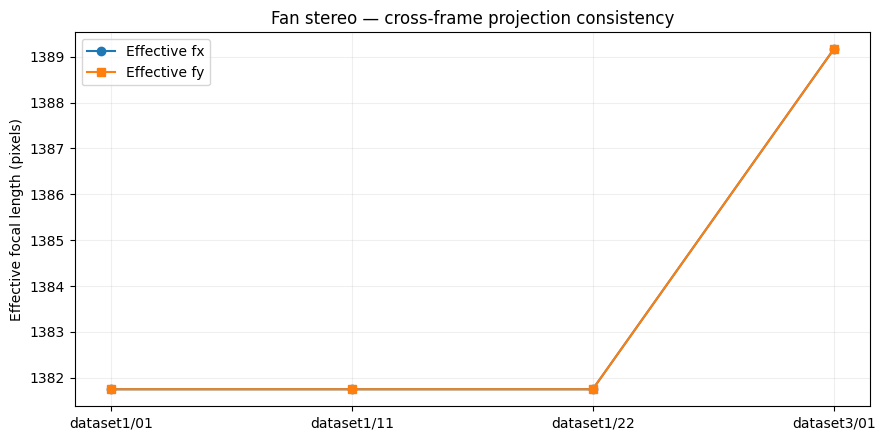


CRDL C3-01 — SECTION 3 SUMMARY
Frames checked: 4
Projection-compatible frames: 4
Physical units verified: NO
Independent camera calibration verified: NO
Metric training authorized: NO
Saved reports: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-01_section03_20261020T050850_399530Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-01
# SECTION 3: FAN CAMERA PROJECTION CONSISTENCY
# DEVELOPMENT FRAMES ONLY | NO METRIC UNIT ASSUMPTIONS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from scipy.io import loadmat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import hashlib

ROOT = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "fan_stereo_pothole/"
    "stereo_pothole_datasets-master"
)

AUDITS = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

assert ROOT.is_dir() and AUDITS.is_dir()

# Explicit development-only frames.
# Historical dataset2 is NEVER accessed.
FRAMES = [
    ("dataset1", "01"),
    ("dataset1", "11"),
    ("dataset1", "22"),
    ("dataset3", "01"),
]

STEP = 12
results = []

# ------------------------------------------------------------
# 1. ROBUST ONE-DIMENSIONAL PROJECTION FIT
# ------------------------------------------------------------

def robust_projection_fit(ratio, pixels):

    A = np.column_stack([
        ratio,
        np.ones_like(ratio)
    ])

    keep = np.ones(
        len(ratio), dtype=bool
    )

    for _ in range(5):

        coeff = np.linalg.lstsq(
            A[keep],
            pixels[keep],
            rcond=None
        )[0]

        residual = pixels - A @ coeff
        center = np.median(residual[keep])

        mad = np.median(
            np.abs(residual[keep] - center)
        )

        sigma = max(
            1.4826 * mad, 0.25
        )

        new_keep = (
            np.abs(residual - center)
            <= max(3.5 * sigma, 1.0)
        )

        if new_keep.sum() < 500:
            break

        keep = new_keep

    coeff = np.linalg.lstsq(
        A[keep],
        pixels[keep],
        rcond=None
    )[0]

    predicted = A @ coeff
    error = np.abs(pixels - predicted)

    return {
        "f": float(coeff[0]),
        "c": float(coeff[1]),
        "median_error_px": float(
            np.median(error)
        ),
        "p95_error_px": float(
            np.percentile(error, 95)
        ),
        "inlier_fraction": float(
            keep.mean()
        ),
    }

# ------------------------------------------------------------
# 2. VERIFY MULTIPLE STEREO FRAMES
# ------------------------------------------------------------

for dataset, frame in FRAMES:

    base = ROOT / dataset

    DISP = base / "disp" / f"{frame}.mat"
    XYZ = base / "ptcloud" / f"{frame}.mat"

    assert DISP.is_file()
    assert XYZ.is_file()

    disp = loadmat(
        DISP, variable_names=["disp"]
    )["disp"]

    xyz = loadmat(
        XYZ, variable_names=["xyzPoints"]
    )["xyzPoints"]

    h, w = disp.shape

    assert xyz.shape == (h, w, 3)

    # Bounded sampling across the image.
    dd = disp[::STEP, ::STEP]
    xx = xyz[::STEP, ::STEP, 0]
    yy = xyz[::STEP, ::STEP, 1]
    zz = xyz[::STEP, ::STEP, 2]

    rows = np.broadcast_to(
        np.arange(0, h, STEP)[:, None],
        dd.shape
    )

    cols = np.broadcast_to(
        np.arange(0, w, STEP)[None, :],
        dd.shape
    )

    valid = (
        np.isfinite(dd)
        & np.isfinite(xx)
        & np.isfinite(yy)
        & np.isfinite(zz)
        & (dd > 0)
        & (zz > 1e-9)
    )

    if valid.sum() < 1000:
        raise ValueError(
            f"Insufficient valid data: {dataset}/{frame}"
        )

    # Image/3D ratios.
    x_ratio = xx[valid] / zz[valid]
    y_ratio = yy[valid] / zz[valid]

    u = cols[valid].astype(float)
    v = rows[valid].astype(float)

    fit_x = robust_projection_fit(
        x_ratio, u
    )

    fit_y = robust_projection_fit(
        y_ratio, v
    )

    # This is f*B in stored coordinate units.
    # It does NOT certify metres or millimetres.
    products = (
        dd[valid].astype(float)
        * zz[valid].astype(float)
    )

    product_median = float(
        np.median(products)
    )

    product_relative_spread = float(
        np.percentile(
            np.abs(products - product_median), 95
        ) / max(abs(product_median), 1e-9)
    )

    # Baseline estimate in UNKNOWN XYZ units.
    fx = fit_x["f"]

    baseline_raw = (
        product_median / abs(fx)
        if abs(fx) > 1e-9
        else None
    )

    result = {
        "dataset": dataset,
        "frame": frame,
        "sampled_valid_points": int(valid.sum()),
        "fx_effective_px": fit_x["f"],
        "fy_effective_px": fit_y["f"],
        "cx_effective_px": fit_x["c"],
        "cy_effective_px": fit_y["c"],
        "horizontal_p95_error_px":
            fit_x["p95_error_px"],
        "vertical_p95_error_px":
            fit_y["p95_error_px"],
        "horizontal_inlier_fraction":
            fit_x["inlier_fraction"],
        "vertical_inlier_fraction":
            fit_y["inlier_fraction"],
        "focal_baseline_product_raw":
            product_median,
        "product_relative_spread_p95":
            product_relative_spread,
        "inferred_baseline_unknown_units":
            baseline_raw,
        "metric_scale_verified": False,
    }

    # Diagnostic thresholds, not physical calibration.
    result["projection_compatible"] = bool(
        fit_x["p95_error_px"] < 2.0
        and fit_y["p95_error_px"] < 2.0
        and product_relative_spread < 0.01
    )

    results.append(result)

    print(f"\n{dataset} / Frame {frame}")
    print("Effective fx:", round(fit_x["f"], 3))
    print("Effective fy:", round(fit_y["f"], 3))
    print("Effective cx:", round(fit_x["c"], 3))
    print("Effective cy:", round(fit_y["c"], 3))
    print(
        "Horizontal p95 error:",
        round(fit_x["p95_error_px"], 4), "pixels"
    )
    print(
        "Vertical p95 error:",
        round(fit_y["p95_error_px"], 4), "pixels"
    )
    print(
        "Inferred baseline (unknown units):",
        baseline_raw
    )
    print(
        "Projection compatible:",
        result["projection_compatible"]
    )

# ------------------------------------------------------------
# 3. SHOW CROSS-FRAME COMPARISON
# ------------------------------------------------------------

df = pd.DataFrame(results)

display(df[[
    "dataset",
    "frame",
    "fx_effective_px",
    "fy_effective_px",
    "horizontal_p95_error_px",
    "vertical_p95_error_px",
    "inferred_baseline_unknown_units",
    "projection_compatible"
]])

fig, ax = plt.subplots(figsize=(9, 4.5))

labels = (
    df["dataset"] + "/" + df["frame"]
)

ax.plot(
    labels,
    df["fx_effective_px"],
    "o-",
    label="Effective fx"
)

ax.plot(
    labels,
    df["fy_effective_px"],
    "s-",
    label="Effective fy"
)

ax.set_ylabel("Effective focal length (pixels)")
ax.set_title(
    "Fan stereo — cross-frame projection consistency"
)
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()

# ------------------------------------------------------------
# 4. SAVE VERSIONED SCIENTIFIC OUTPUTS
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = AUDITS / f"C3-01_section03_{stamp}"
OUT.mkdir(exist_ok=False)

csv_path = OUT / "fan_projection_comparison.csv"
df.to_csv(csv_path, index=False)

figure_path = OUT / "fan_projection_comparison.png"
fig.savefig(figure_path, dpi=150)
plt.show()
plt.close(fig)

report = {
    "milestone": "C3-01",
    "section": 3,
    "method": "inferred_pinhole_projection_check",
    "development_frames": results,
    "units": "UNCERTIFIED",
    "camera_intrinsics": "INFERRED_NOT_INDEPENDENT",
    "baseline": "INFERRED_UNKNOWN_UNITS",
    "physical_training_authorized": False,
    "protected_dataset2_accessed": False,
    "warning": (
        "Projection consistency may be an algebraic "
        "property of reconstructed point clouds. "
        "It does not validate physical units or "
        "independent 3D accuracy."
    ),
}

json_path = OUT / "fan_projection_evidence.json"

json_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

checksums = []

for path in [csv_path, json_path, figure_path]:

    sha = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    checksums.append(
        f"{sha}  {path.name}"
    )

(OUT / "checksums.sha256").write_text(
    "\n".join(checksums) + "\n",
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("CRDL C3-01 — SECTION 3 SUMMARY")
print("=" * 65)

print("Frames checked:", len(results))
print(
    "Projection-compatible frames:",
    sum(r["projection_compatible"] for r in results)
)
print("Physical units verified: NO")
print("Independent camera calibration verified: NO")
print("Metric training authorized: NO")
print("Saved reports:", OUT)
print("=" * 65)



dataset1 / Frame 01


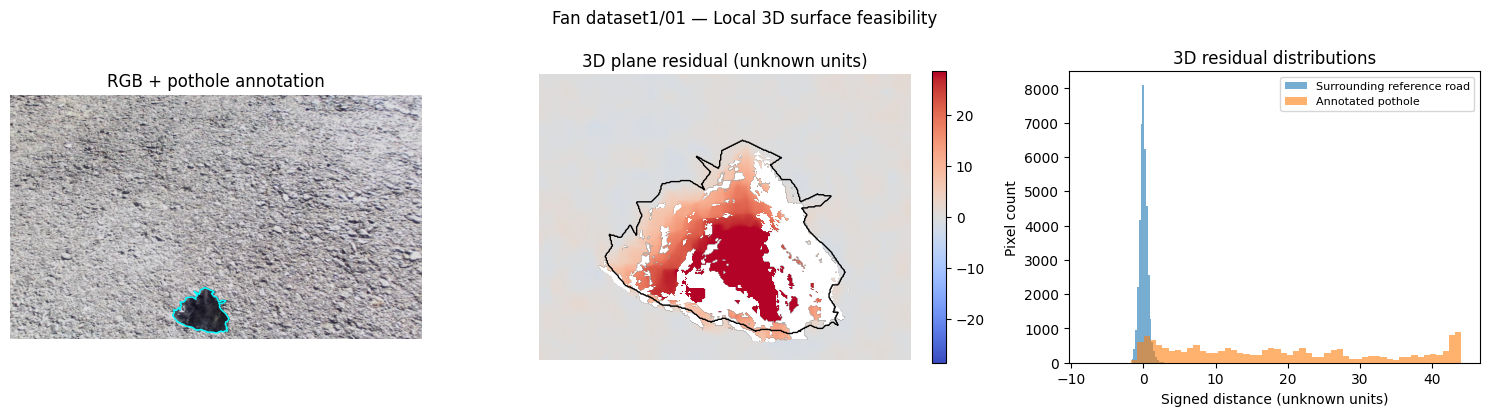

Road support points: 11907
Reference-ring absolute p95: 1.0924075891435296
Pothole absolute p95: 43.25678311701643
Units: NOT CERTIFIED

dataset1 / Frame 11


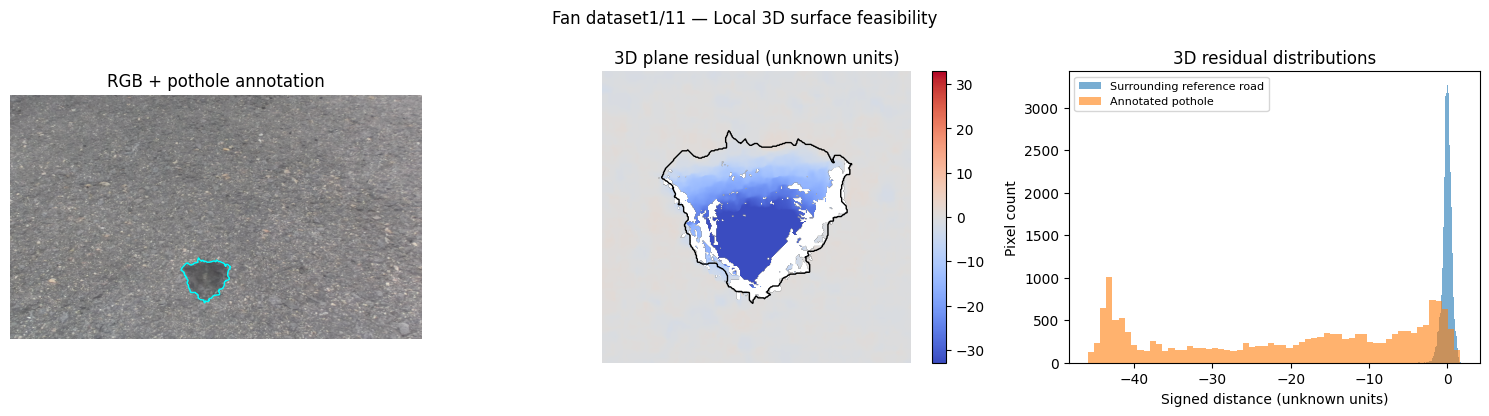

Road support points: 11887
Reference-ring absolute p95: 1.1644426632300293
Pothole absolute p95: 43.74908018940716
Units: NOT CERTIFIED

dataset3 / Frame 01


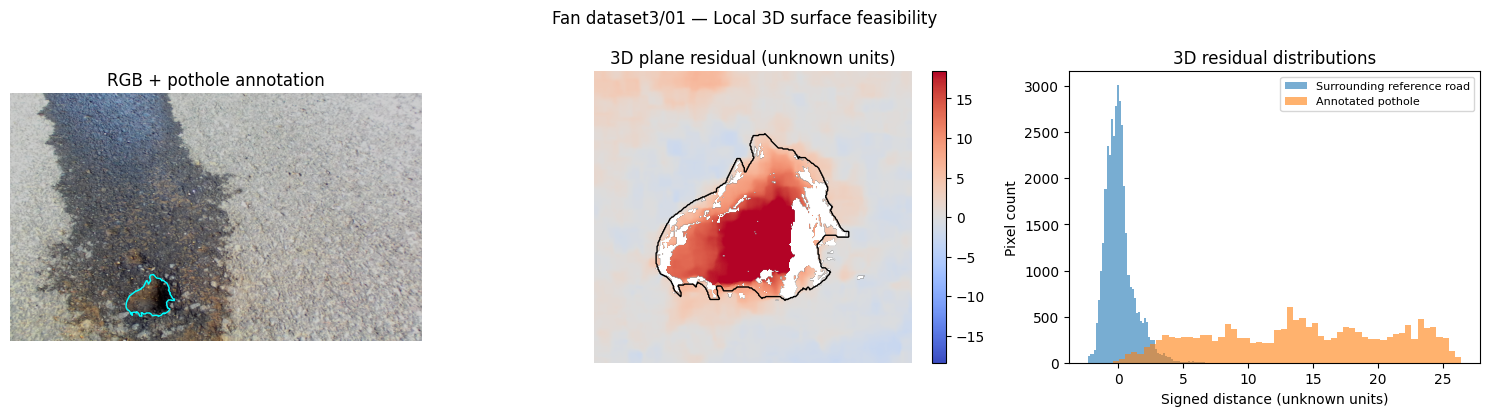

Road support points: 11687
Reference-ring absolute p95: 2.2496258218134537
Pothole absolute p95: 24.361326968837837
Units: NOT CERTIFIED

C3-01 SECTION 4 COMPLETE
Frames analyzed: 3
3D fitting diagnostics saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-01_section04_20261020T051421_441716Z
Metric depression labels exported: NO
Metric training authorized: NO


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-01
# SECTION 4: 3D ROAD-SURFACE FITTING FEASIBILITY
# Version: 1.0
# NO METRIC LABELS | DEVELOPMENT FRAMES ONLY
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from scipy.io import loadmat
from scipy.ndimage import distance_transform_edt
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import json
import hashlib

ROOT = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "fan_stereo_pothole/"
    "stereo_pothole_datasets-master"
)

AUDIT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

# Historical dataset2 is excluded.
FRAMES = [
    ("dataset1", "01"),
    ("dataset1", "11"),
    ("dataset3", "01"),
]

rng = np.random.default_rng(309)

# ------------------------------------------------------------
# 1. ROBUST 3D REFERENCE PLANE
# ------------------------------------------------------------

def fit_reference_plane(points, max_points=12000):

    if len(points) < 200:
        raise ValueError("Insufficient road support")

    if len(points) > max_points:
        index = rng.choice(
            len(points), max_points, replace=False
        )
        points = points[index]

    keep = np.ones(len(points), dtype=bool)

    for iteration in range(6):

        current = points[keep]
        center = np.median(current, axis=0)

        _, _, vh = np.linalg.svd(
            current - center,
            full_matrices=False
        )

        normal = vh[-1]
        normal /= np.linalg.norm(normal)

        errors = (points - center) @ normal

        midpoint = np.median(errors[keep])
        mad = np.median(
            np.abs(errors[keep] - midpoint)
        )

        sigma = max(1.4826 * mad, 1e-6)

        updated = (
            np.abs(errors - midpoint)
            <= 3.5 * sigma
        )

        if updated.sum() < 200:
            break

        keep = updated

    # Refit on final accepted support.
    selected = points[keep]
    center = selected.mean(axis=0)

    _, _, vh = np.linalg.svd(
        selected - center,
        full_matrices=False
    )

    normal = vh[-1]
    normal /= np.linalg.norm(normal)

    return center, normal, int(len(selected))

# ------------------------------------------------------------
# 2. LOAD DEVELOPMENT-ONLY DATA
# ------------------------------------------------------------

results = []

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = AUDIT / f"C3-01_section04_{stamp}"
OUT.mkdir(exist_ok=False)

for dataset, frame in FRAMES:

    print(f"\n{dataset} / Frame {frame}")

    base = ROOT / dataset

    disp_path = base / "disp" / f"{frame}.mat"
    xyz_path = base / "ptcloud" / f"{frame}.mat"
    mask_path = base / "label" / f"{frame}.png"
    rgb_path = base / "rgb" / f"{frame}.png"

    disp = loadmat(
        disp_path, variable_names=["disp"]
    )["disp"]

    xyz = loadmat(
        xyz_path, variable_names=["xyzPoints"]
    )["xyzPoints"]

    with Image.open(mask_path) as im:
        label = np.asarray(im.convert("RGB"))

    with Image.open(rgb_path) as im:
        rgb = np.asarray(im.convert("RGB"))

    h, w = disp.shape

    assert xyz.shape == (h, w, 3)
    assert rgb.shape[:2] == (h, w)
    assert label.shape[:2] == (h, w)

    # Fan dataset1 label example uses colored
    # foreground against black background.
    mask = np.any(label != 0, axis=2)

    valid = (
        np.isfinite(xyz).all(axis=2)
        & np.isfinite(disp)
        & (disp > 0)
        & (xyz[:, :, 2] > 0)
    )

    if mask.sum() < 100:
        raise ValueError(
            f"Empty or unexpected label: {dataset}/{frame}"
        )

    # --------------------------------------------------------
    # 3. SELECT HEALTHY ROAD SUPPORT
    # --------------------------------------------------------

    distance = distance_transform_edt(~mask)

    ring = (
        (distance >= 8)
        & (distance <= 55)
        & valid
    )

    support_points = xyz[ring]

    if len(support_points) < 500:
        raise ValueError(
            "Insufficient valid surrounding road points"
        )

    center, normal, support_n = (
        fit_reference_plane(support_points)
    )

    # --------------------------------------------------------
    # 4. COMPUTE SIGNED 3D DISTANCE TO THE PLANE
    # --------------------------------------------------------

    # Plane normal sign is arbitrary.
    # These are NOT certified pothole depressions.
    signed = np.einsum(
        "ijk,k->ij",
        xyz - center,
        normal
    )

    signed[~valid] = np.nan

    pothole_values = signed[mask & valid]
    ring_values = signed[ring]

    if len(pothole_values) < 100:
        raise ValueError("Insufficient pothole geometry")

    stats = {
        "dataset": dataset,
        "frame": frame,
        "mask_pixels": int(mask.sum()),
        "valid_fraction_in_mask": float(
            valid[mask].mean()
        ),
        "road_support_pixels": support_n,
        "normal_xyz": normal.tolist(),
        "signed_median_inside_mask": float(
            np.median(pothole_values)
        ),
        "absolute_median_inside_mask": float(
            np.median(np.abs(pothole_values))
        ),
        "absolute_p95_inside_mask": float(
            np.percentile(np.abs(pothole_values), 95)
        ),
        "absolute_p95_reference_ring": float(
            np.percentile(np.abs(ring_values), 95)
        ),
        "units": "XYZ_UNITS_UNVERIFIED",
        "physical_depression_certified": False,
        "fit_type": "ROBUST_LOCAL_3D_PLANE_DIAGNOSTIC",
    }

    results.append(stats)

    # --------------------------------------------------------
    # 5. PLOT LOCAL REFERENCE GEOMETRY
    # --------------------------------------------------------

    ys, xs = np.where(mask)

    margin = 65

    y0 = max(0, int(ys.min()) - margin)
    y1 = min(h, int(ys.max()) + margin + 1)
    x0 = max(0, int(xs.min()) - margin)
    x1 = min(w, int(xs.max()) + margin + 1)

    local = signed[y0:y1, x0:x1]
    local_mask = mask[y0:y1, x0:x1]

    local_valid = local[np.isfinite(local)]

    scale = max(
        float(np.percentile(
            np.abs(local_valid), 95
        )),
        1e-6
    )

    fig, axes = plt.subplots(
        1, 3, figsize=(15, 4.2)
    )

    axes[0].imshow(rgb)
    axes[0].contour(
        mask.astype(float),
        levels=[0.5],
        colors="cyan",
        linewidths=1
    )
    axes[0].set_title("RGB + pothole annotation")
    axes[0].axis("off")

    im = axes[1].imshow(
        local,
        cmap="coolwarm",
        vmin=-scale,
        vmax=scale
    )

    axes[1].contour(
        local_mask.astype(float),
        levels=[0.5],
        colors="black",
        linewidths=1
    )

    axes[1].set_title(
        "3D plane residual (unknown units)"
    )
    axes[1].axis("off")
    fig.colorbar(im, ax=axes[1], fraction=0.046)

    axes[2].hist(
        ring_values,
        bins=60,
        alpha=0.6,
        label="Surrounding reference road"
    )

    axes[2].hist(
        pothole_values,
        bins=60,
        alpha=0.6,
        label="Annotated pothole"
    )

    axes[2].set_xlabel(
        "Signed distance (unknown units)"
    )
    axes[2].set_ylabel("Pixel count")
    axes[2].set_title("3D residual distributions")
    axes[2].legend(fontsize=8)

    fig.suptitle(
        f"Fan {dataset}/{frame} — "
        "Local 3D surface feasibility"
    )

    fig.tight_layout()

    figure_file = (
        OUT / f"{dataset}_{frame}_3d_surface.png"
    )

    fig.savefig(
        figure_file, dpi=140,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Road support points:", support_n)
    print(
        "Reference-ring absolute p95:",
        stats["absolute_p95_reference_ring"]
    )
    print(
        "Pothole absolute p95:",
        stats["absolute_p95_inside_mask"]
    )
    print("Units: NOT CERTIFIED")

# ------------------------------------------------------------
# 6. SAVE EVIDENCE — NOT TRAINING TARGETS
# ------------------------------------------------------------

report = {
    "milestone": "C3-01",
    "section": 4,
    "method": "robust_local_3d_plane_feasibility",
    "results": results,
    "physical_units_verified": False,
    "plane_sign_orientation_verified": False,
    "road_relative_training_labels_exported": False,
    "physical_training_authorized": False,
    "protected_dataset2_accessed": False,
    "warning": (
        "Signed 3D residuals are exploratory. "
        "They are not yet validated road-relative "
        "depression measurements."
    ),
}

report_file = OUT / "fan_3d_surface_feasibility.json"

report_file.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

hash_lines = []

for path in sorted(OUT.iterdir()):
    if path.is_file():
        digest = hashlib.sha256(
            path.read_bytes()
        ).hexdigest()
        hash_lines.append(
            f"{digest}  {path.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(hash_lines) + "\n",
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("C3-01 SECTION 4 COMPLETE")
print("=" * 65)
print("Frames analyzed:", len(results))
print("3D fitting diagnostics saved:", OUT)
print("Metric depression labels exported: NO")
print("Metric training authorized: NO")
print("=" * 65)


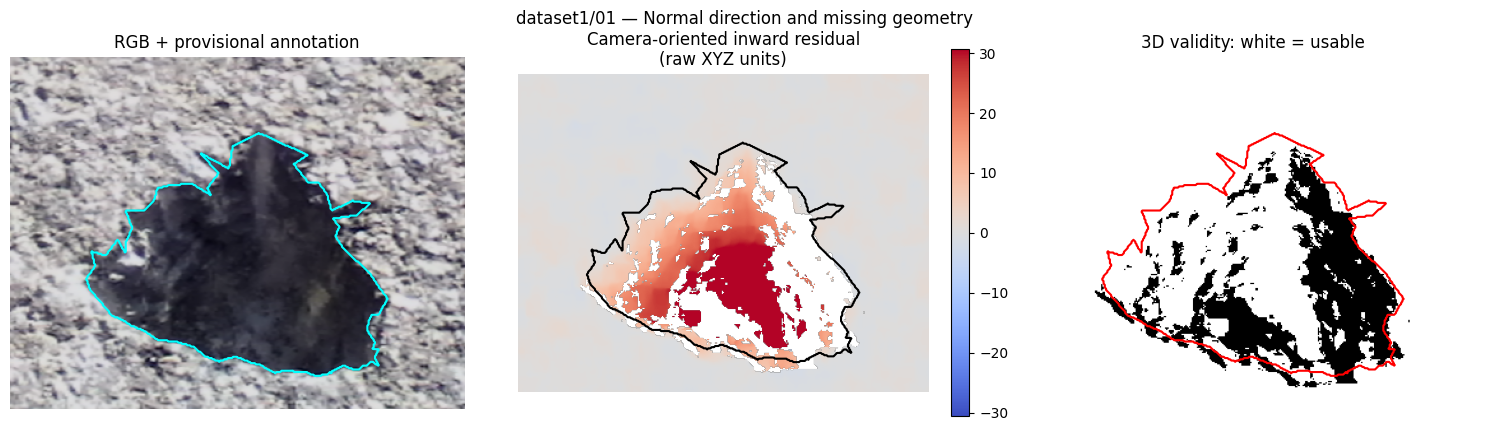


dataset1/01
Valid pothole geometry: 60.83 %
Camera-oriented inward median: 17.365 raw units
Healthy-road absolute P95: 1.091
Worst tested holdout P95: 1.3992957634966114


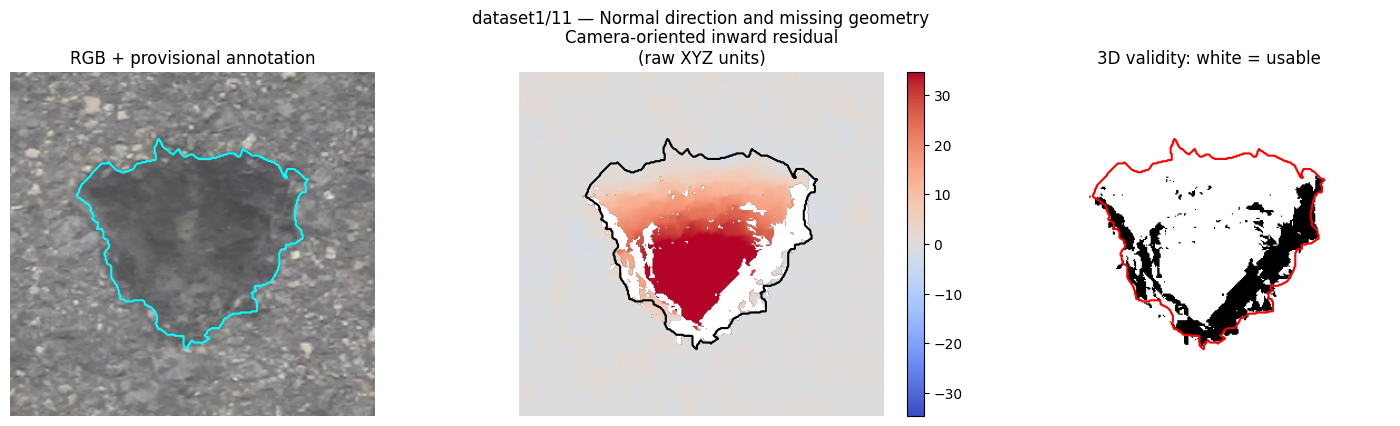


dataset1/11
Valid pothole geometry: 74.38 %
Camera-oriented inward median: 17.411 raw units
Healthy-road absolute P95: 1.166
Worst tested holdout P95: 1.3977930646732748


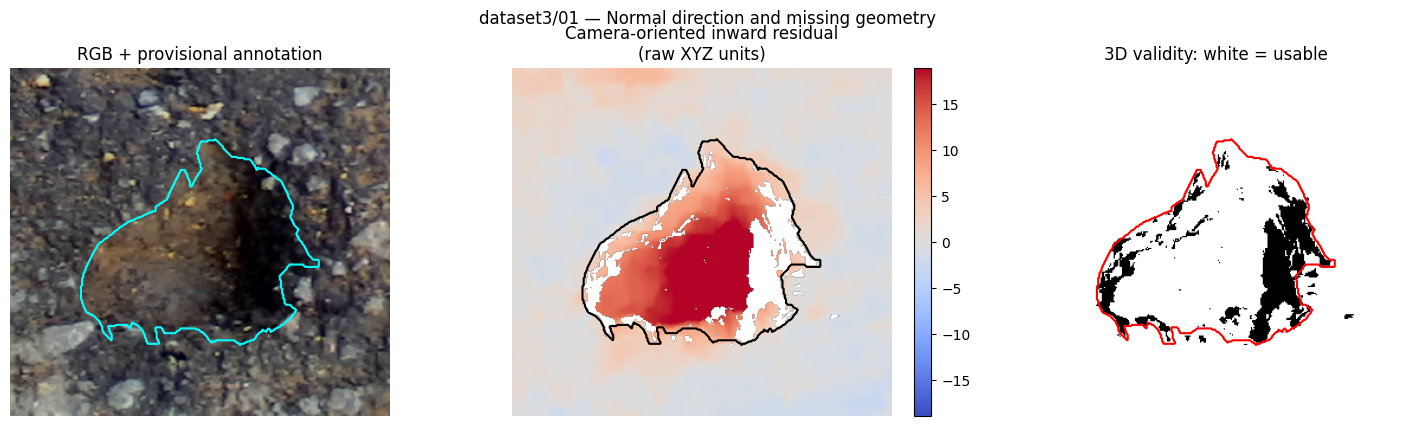


dataset3/01
Valid pothole geometry: 75.16 %
Camera-oriented inward median: 14.107 raw units
Healthy-road absolute P95: 2.246
Worst tested holdout P95: 4.183579210511433

C3-01 SECTION 5 COMPLETE
Frames inspected: 3
Physical units verified: NO
Metric training authorized: NO
Reports: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-01_section05_20261020T052734_099324Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-01
# SECTION 5: 3D NORMAL ORIENTATION AND QUALITY AUDIT
# DEVELOPMENT ONLY | NO METRIC LABEL GENERATION
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from scipy.io import loadmat
from scipy.ndimage import distance_transform_edt
from PIL import Image

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import hashlib
import json

ROOT = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "fan_stereo_pothole/"
    "stereo_pothole_datasets-master"
)

AUDIT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

FRAMES = [
    ("dataset1", "01"),
    ("dataset1", "11"),
    ("dataset3", "01"),
]

assert ROOT.is_dir() and AUDIT.is_dir()

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = AUDIT / f"C3-01_section05_{stamp}"
OUT.mkdir(exist_ok=False)


# ------------------------------------------------------------
# 1. ROBUST PLANE FIT WITH CONSISTENT NORMAL DIRECTION
# ------------------------------------------------------------

def fit_road_plane(points, seed):

    points = np.asarray(points, dtype=np.float64)

    if len(points) < 500:
        raise ValueError("Insufficient road support")

    if len(points) > 14000:
        rng = np.random.default_rng(seed)
        idx = rng.choice(
            len(points), 14000, replace=False
        )
        points = points[idx]

    keep = np.ones(len(points), dtype=bool)

    for _ in range(7):

        selected = points[keep]
        center = np.median(selected, axis=0)

        _, _, vh = np.linalg.svd(
            selected - center,
            full_matrices=False
        )

        normal = vh[-1]
        normal /= np.linalg.norm(normal)

        errors = (points - center) @ normal
        median = np.median(errors[keep])

        mad = np.median(
            np.abs(errors[keep] - median)
        )

        threshold = max(
            3.5 * 1.4826 * mad,
            1e-6
        )

        new_keep = (
            np.abs(errors - median) <= threshold
        )

        if new_keep.sum() < 500:
            break

        keep = new_keep

    selected = points[keep]
    center = selected.mean(axis=0)

    _, _, vh = np.linalg.svd(
        selected - center,
        full_matrices=False
    )

    normal = vh[-1]
    normal /= np.linalg.norm(normal)

    # Provisional convention:
    # Assume the XYZ coordinate origin is the camera.
    # Orient the plane normal toward that origin.
    if np.dot(normal, -center) < 0:
        normal = -normal

    return center, normal, int(len(selected))


# ------------------------------------------------------------
# 2. INSPECT THREE DEVELOPMENT-ONLY FRAMES
# ------------------------------------------------------------

results = []

for frame_idx, (dataset, frame) in enumerate(FRAMES):

    base = ROOT / dataset

    disp = loadmat(
        base / "disp" / f"{frame}.mat",
        variable_names=["disp"]
    )["disp"]

    xyz = loadmat(
        base / "ptcloud" / f"{frame}.mat",
        variable_names=["xyzPoints"]
    )["xyzPoints"]

    with Image.open(base / "label" / f"{frame}.png") as im:
        label = np.asarray(im.convert("RGB"))

    with Image.open(base / "rgb" / f"{frame}.png") as im:
        rgb = np.asarray(im.convert("RGB"))

    h, w = disp.shape

    assert xyz.shape == (h, w, 3)
    assert label.shape[:2] == (h, w)
    assert rgb.shape[:2] == (h, w)

    # Provisional interpretation of the label PNG.
    mask = np.any(label != 0, axis=2)

    valid = (
        np.isfinite(xyz).all(axis=2)
        & np.isfinite(disp)
        & (disp > 0)
        & (xyz[:, :, 2] > 0)
    )

    if mask.sum() < 100:
        raise ValueError(
            f"Unexpected empty mask: {dataset}/{frame}"
        )

    distance = distance_transform_edt(~mask)

    ring = (
        (distance >= 8)
        & (distance <= 55)
        & valid
    )

    if ring.sum() < 1000:
        raise ValueError(
            "Insufficient healthy-road support"
        )

    center, normal, support_n = fit_road_plane(
        xyz[ring],
        seed=309 + frame_idx
    )

    # Positive means inward relative to our
    # provisional camera-facing normal.
    # Values are NOT verified physical depths.
    inward = -np.einsum(
        "ijk,k->ij",
        xyz - center,
        normal
    )

    inward[~valid] = np.nan

    inside = inward[mask & valid]
    road = inward[ring]

    if inside.size < 500:
        raise ValueError(
            "Insufficient valid pothole points"
        )

    # --------------------------------------------------------
    # 3. SPATIAL HOLDOUT TEST
    # --------------------------------------------------------

    # Divide the surrounding-road ring into four
    # angular sectors around the pothole.
    # Fit using three sectors; evaluate the fourth.

    yy, xx = np.indices(mask.shape)
    my, mx = np.mean(np.where(mask), axis=1)

    angle = np.arctan2(
        yy - my,
        xx - mx
    )

    sectors = np.mod(
        np.floor(
            (angle + np.pi) / (np.pi / 2)
        ).astype(int),
        4
    )

    holdout_results = []

    for fold in range(4):

        train = ring & (sectors != fold)
        test = ring & (sectors == fold)

        if train.sum() < 500 or test.sum() < 150:

            holdout_results.append({
                "sector": fold,
                "status": "INSUFFICIENT_SUPPORT",
                "test_pixels": int(test.sum())
            })

            continue

        test_center, test_normal, _ = fit_road_plane(
            xyz[train],
            seed=3090 + 10 * frame_idx + fold
        )

        errors = (
            xyz[test] - test_center
        ) @ test_normal

        holdout_results.append({
            "sector": fold,
            "status": "TESTED",
            "test_pixels": int(test.sum()),
            "absolute_p95_raw": float(
                np.percentile(np.abs(errors), 95)
            )
        })

    tested = [
        x["absolute_p95_raw"]
        for x in holdout_results
        if x["status"] == "TESTED"
    ]

    # --------------------------------------------------------
    # 4. RECORD QUALITY AND GEOMETRY
    # --------------------------------------------------------

    result = {
        "dataset": dataset,
        "frame": frame,
        "mask_pixels": int(mask.sum()),
        "usable_mask_fraction": float(
            valid[mask].mean()
        ),
        "missing_mask_fraction": float(
            (~valid[mask]).mean()
        ),
        "fit_support_points": support_n,
        "camera_facing_normal": normal.tolist(),
        "inward_median_raw": float(
            np.median(inside)
        ),
        "inward_positive_fraction": float(
            np.mean(inside > 0)
        ),
        "inward_p95_positive_raw": float(
            np.percentile(
                np.maximum(inside, 0), 95
            )
        ),
        "healthy_road_abs_p95_raw": float(
            np.percentile(np.abs(road), 95)
        ),
        "spatial_holdout_results": holdout_results,
        "spatial_holdout_max_p95_raw": (
            max(tested) if tested else None
        ),
        "coordinate_units": "UNVERIFIED",
        "camera_origin": "ASSUMED",
        "mask_semantics": "NONBLACK_PROVISIONAL",
        "physical_depression_verified": False,
        "training_label_exported": False,
    }

    results.append(result)

    # --------------------------------------------------------
    # 5. VISUALIZE RESIDUALS AND MISSING MEASUREMENTS
    # --------------------------------------------------------

    ys, xs = np.where(mask)

    y0 = max(0, int(ys.min()) - 60)
    y1 = min(h, int(ys.max()) + 61)
    x0 = max(0, int(xs.min()) - 60)
    x1 = min(w, int(xs.max()) + 61)

    sub = inward[y0:y1, x0:x1]
    sub_mask = mask[y0:y1, x0:x1]

    finite = sub[np.isfinite(sub)]

    scale = max(
        float(np.percentile(np.abs(finite), 95)),
        1e-6
    )

    fig, axes = plt.subplots(
        1, 3, figsize=(15, 4.3)
    )

    axes[0].imshow(
        rgb[y0:y1, x0:x1]
    )
    axes[0].contour(
        sub_mask.astype(float),
        levels=[0.5],
        colors="cyan"
    )
    axes[0].set_title(
        "RGB + provisional annotation"
    )

    im = axes[1].imshow(
        sub,
        cmap="coolwarm",
        vmin=-scale,
        vmax=scale
    )
    axes[1].contour(
        sub_mask.astype(float),
        levels=[0.5],
        colors="black"
    )
    axes[1].set_title(
        "Camera-oriented inward residual\n"
        "(raw XYZ units)"
    )

    fig.colorbar(
        im, ax=axes[1], fraction=0.046
    )

    axes[2].imshow(
        valid[y0:y1, x0:x1],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[2].contour(
        sub_mask.astype(float),
        levels=[0.5],
        colors="red"
    )
    axes[2].set_title(
        "3D validity: white = usable"
    )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"{dataset}/{frame} — "
        "Normal direction and missing geometry"
    )

    fig.tight_layout()

    fig.savefig(
        OUT / (
            f"{dataset}_{frame}_orientation_quality.png"
        ),
        dpi=140,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(f"\n{dataset}/{frame}")
    print(
        "Valid pothole geometry:",
        round(100 * result["usable_mask_fraction"], 2),
        "%"
    )
    print(
        "Camera-oriented inward median:",
        round(result["inward_median_raw"], 3),
        "raw units"
    )
    print(
        "Healthy-road absolute P95:",
        round(result["healthy_road_abs_p95_raw"], 3)
    )
    print(
        "Worst tested holdout P95:",
        result["spatial_holdout_max_p95_raw"]
    )


# ------------------------------------------------------------
# 6. SAVE VERSIONED REPORTS
# ------------------------------------------------------------

report = {
    "milestone": "C3-01",
    "section": 5,
    "method":
        "camera_facing_normal_and_spatial_road_holdout",
    "source_data_modified": False,
    "coordinate_units_verified": False,
    "normal_orientation_is_heuristic": True,
    "metric_training_authorized": False,
    "protected_dataset2_accessed": False,
    "warning": (
        "Positive inward residual is not certified "
        "pothole depth. Missing geometry must be "
        "masked, not replaced by zero."
    ),
    "results": results,
}

json_path = OUT / "orientation_validity_report.json"

json_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

summary = pd.DataFrame([
    {
        k: v for k, v in record.items()
        if k != "spatial_holdout_results"
    }
    for record in results
])

summary.to_csv(
    OUT / "orientation_quality_summary.csv",
    index=False
)

checksum_lines = []

for path in sorted(OUT.iterdir()):

    if path.is_file():

        digest = hashlib.sha256(
            path.read_bytes()
        ).hexdigest()

        checksum_lines.append(
            f"{digest}  {path.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(checksum_lines) + "\n",
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("C3-01 SECTION 5 COMPLETE")
print("=" * 65)

print("Frames inspected:", len(results))
print("Physical units verified: NO")
print("Metric training authorized: NO")
print("Reports:", OUT)

print("=" * 65)


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-01
# SECTION 6: FAN PHYSICAL SCALE EVIDENCE
# No training | No metric labels | Read-only input reports
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
import numpy as np
import pandas as pd
import hashlib
import json

ROOT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

# Exact previously completed research runs.
RUN03 = ROOT / (
    "C3-01_section03_20261020T050850_399530Z"
)

RUN05 = ROOT / (
    "C3-01_section05_20261020T052734_099324Z"
)

# ------------------------------------------------------------
# 1. VERIFY ORIGINAL EXPERIMENT REPORTS
# ------------------------------------------------------------

def verify_report(folder, filename):

    path = folder / filename
    checksums = folder / "checksums.sha256"

    assert path.is_file()
    assert checksums.is_file()

    expected = {}

    for line in checksums.read_text().splitlines():

        if not line.strip():
            continue

        sha, name = line.split(None, 1)
        name = name.strip()

        if Path(name).name != name:
            raise ValueError("Unsafe checksum entry")

        expected[name] = sha

    assert filename in expected

    actual = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    assert actual == expected[filename], (
        f"Integrity failure: {filename}"
    )

    return json.loads(
        path.read_text(encoding="utf-8")
    ), actual


projection, projection_sha = verify_report(
    RUN03, "fan_projection_evidence.json"
)

quality, quality_sha = verify_report(
    RUN05, "orientation_validity_report.json"
)

assert projection["section"] == 3
assert quality["section"] == 5

print("Previous experiment integrity: PASS")

# ------------------------------------------------------------
# 2. REGISTER INDEPENDENT SOURCE EVIDENCE
# ------------------------------------------------------------

# This is a reported hardware baseline,
# not a recovered dataset-specific calibration.
NOMINAL_BASELINE_MM = 120.0

source_evidence = [
    {
        "source": "Fan 2019 pothole research",
        "url": (
            "https://www.ruirangerfan.com/"
            "pdf/tip2019_fan.pdf"
        ),
        "finding": "Experimental camera reported as ZED",
    },
    {
        "source": "Fan doctoral research",
        "url": (
            "https://research-information.bris.ac.uk/"
            "files/170036616/"
            "Final_Copy_2018_09_25_Fan_R_PhD.pdf"
        ),
        "finding": "ZED stereo baseline reported as 120 mm",
    },
    {
        "source": "Stereolabs calibration documentation",
        "url": (
            "https://docs.stereolabs.com/docs/"
            "development/zed-sdk/modules/"
            "camera/camera-calibration"
        ),
        "finding": "Stereo baseline represented in millimetres",
    },
]

# ------------------------------------------------------------
# 3. GROUP INFERRED BASELINES BY DATASET
# ------------------------------------------------------------

groups = defaultdict(list)

for frame in projection["development_frames"]:

    dataset = frame["dataset"]

    if dataset not in {"dataset1", "dataset3"}:
        raise ValueError("Unexpected dataset partition")

    baseline = float(
        frame["inferred_baseline_unknown_units"]
    )

    if not np.isfinite(baseline) or baseline <= 0:
        raise ValueError("Invalid inferred baseline")

    groups[dataset].append(baseline)

rows = []

print("\nFAN HARDWARE BASELINE COMPARISON")
print("=" * 64)

for dataset, baselines in sorted(groups.items()):

    values = np.asarray(baselines)

    raw_median = float(np.median(values))

    difference_percent = (
        abs(raw_median - NOMINAL_BASELINE_MM)
        / NOMINAL_BASELINE_MM
        * 100
    )

    # HYPOTHESIS ONLY:
    # Would be mm/raw-unit IF these are the same
    # camera rig and nominal 120 mm is applicable.
    proposed_mm_per_raw = (
        NOMINAL_BASELINE_MM / raw_median
    )

    compatible = difference_percent < 2.0

    rows.append({
        "dataset": dataset,
        "frames_checked": len(values),
        "baseline_raw_median": raw_median,
        "baseline_raw_std": float(
            values.std()
        ),
        "nominal_zed_baseline_mm":
            NOMINAL_BASELINE_MM,
        "difference_percent":
            difference_percent,
        "hypothetical_mm_per_raw":
            proposed_mm_per_raw,
        "nominal_baseline_compatible":
            bool(compatible),
        "actual_capture_units_verified": False,
    })

    print("\n", dataset)
    print("Frames examined:", len(values))
    print("Raw baseline:", round(raw_median, 6))
    print(
        "Deviation from 120:",
        round(difference_percent, 4), "%"
    )
    print(
        "Hypothetical mm/raw factor:",
        round(proposed_mm_per_raw, 7)
    )
    print(
        "Scale status:",
        "PLAUSIBLE — UNVERIFIED"
        if compatible else "NEEDS INVESTIGATION"
    )

# ------------------------------------------------------------
# 4. PRESERVE THE GEOMETRY VALIDITY EVIDENCE
# ------------------------------------------------------------

validity = []

for frame in quality["results"]:

    validity.append({
        "dataset": frame["dataset"],
        "frame": frame["frame"],
        "usable_fraction":
            frame["usable_mask_fraction"],
        "missing_fraction":
            frame["missing_mask_fraction"],
        "worst_holdout_p95_raw":
            frame["spatial_holdout_max_p95_raw"],
        "dense_reference_safe": False,
    })

# ------------------------------------------------------------
# 5. SAVE VERSIONED CALIBRATION-EVIDENCE REPORT
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = ROOT / f"C3-01_section06_{stamp}"
OUT.mkdir(exist_ok=False)

report = {
    "milestone": "C3-01",
    "section": 6,
    "method": "hardware_baseline_provenance_triangulation",
    "source_research": source_evidence,
    "source_run03_sha256": projection_sha,
    "source_run05_sha256": quality_sha,
    "nominal_baseline_mm": NOMINAL_BASELINE_MM,
    "results": rows,
    "geometry_validity": validity,
    "interpretation": (
        "Millimetre units are plausible under the "
        "ZED 120 mm hardware-baseline hypothesis. "
        "The same-rig relationship and exact "
        "capture calibration remain unconfirmed."
    ),
    "actual_calibration_file_verified": False,
    "independent_physical_accuracy_verified": False,
    "metric_supervision_authorized": False,
    "road_relative_training_labels_created": False,
    "source_dataset_modified": False,
    "protected_evaluation_accessed": False,
}

json_path = OUT / "fan_scale_hypothesis.json"

json_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

csv_path = OUT / "fan_scale_comparison.csv"

pd.DataFrame(rows).to_csv(
    csv_path, index=False
)

checksums = []

for path in [json_path, csv_path]:

    sha = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    checksums.append(
        f"{sha}  {path.name}"
    )

(OUT / "checksums.sha256").write_text(
    "\n".join(checksums) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 6. RESEARCH DECISION
# ------------------------------------------------------------

print("\n" + "=" * 64)
print("C3-01 SECTION 6 — CALIBRATION EVIDENCE SUMMARY")
print("=" * 64)

print("Source report integrity: PASS")
print("Hardware-scale hypothesis: TESTED")

print(
    "All sampled partitions compatible:",
    all(r["nominal_baseline_compatible"] for r in rows)
)

print("Exact capture calibration: NOT VERIFIED")
print("Physical accuracy: NOT VERIFIED")
print("Metric supervision authorized: NO")
print("Report saved:", OUT)

print("=" * 64)


Previous experiment integrity: PASS

FAN HARDWARE BASELINE COMPARISON

 dataset1
Frames examined: 3
Raw baseline: 119.438093
Deviation from 120: 0.4683 %
Hypothetical mm/raw factor: 1.0047046
Scale status: PLAUSIBLE — UNVERIFIED

 dataset3
Frames examined: 1
Raw baseline: 119.493103
Deviation from 120: 0.4224 %
Hypothetical mm/raw factor: 1.0042421
Scale status: PLAUSIBLE — UNVERIFIED

C3-01 SECTION 6 — CALIBRATION EVIDENCE SUMMARY
Source report integrity: PASS
Hardware-scale hypothesis: TESTED
All sampled partitions compatible: True
Exact capture calibration: NOT VERIFIED
Physical accuracy: NOT VERIFIED
Metric supervision authorized: NO
Report saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-01_section06_20261020T053313_045228Z


CRDL C3-01 — BUTT ENCODING AUDIT v1.1
Training manifest entries: 20010
Samples selected: 5
Validation and test manifests: NOT OPENED

-------------------------------------------------------
FRAME: frame_14073
RGB shape: (720, 1280, 3)
Depth shape: (224, 320)
Depth dtype: uint8
Depth PNG mode: L
Dimensions match: False
Aspect ratio difference: 0.34921
Width ratio: 4.0
Height ratio: 3.2143
Unique depth values: 256
Raw depth range: 0.0 to 255.0


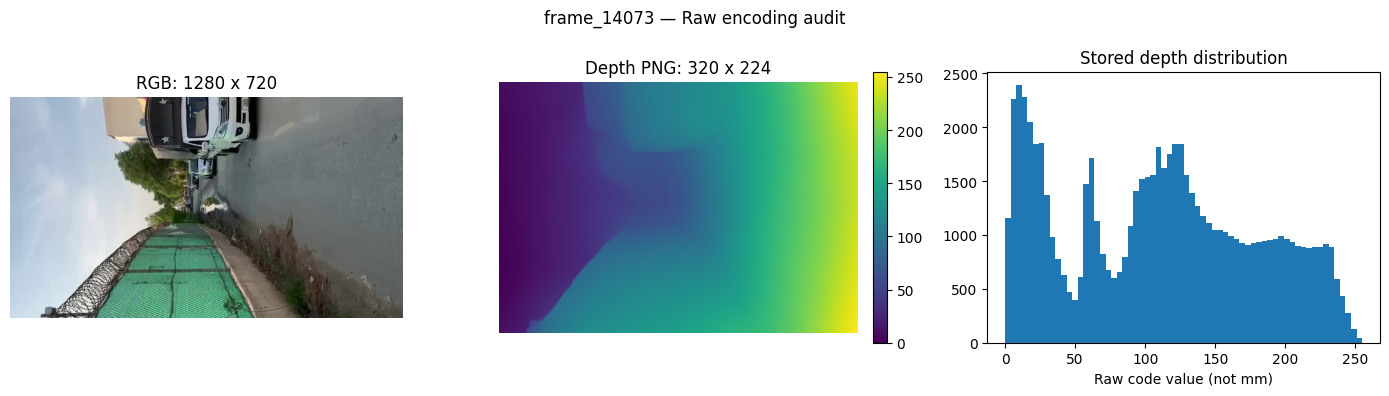


-------------------------------------------------------
FRAME: frame_15058
RGB shape: (720, 1280, 3)
Depth shape: (224, 320)
Depth dtype: uint8
Depth PNG mode: L
Dimensions match: False
Aspect ratio difference: 0.34921
Width ratio: 4.0
Height ratio: 3.2143
Unique depth values: 256
Raw depth range: 0.0 to 255.0


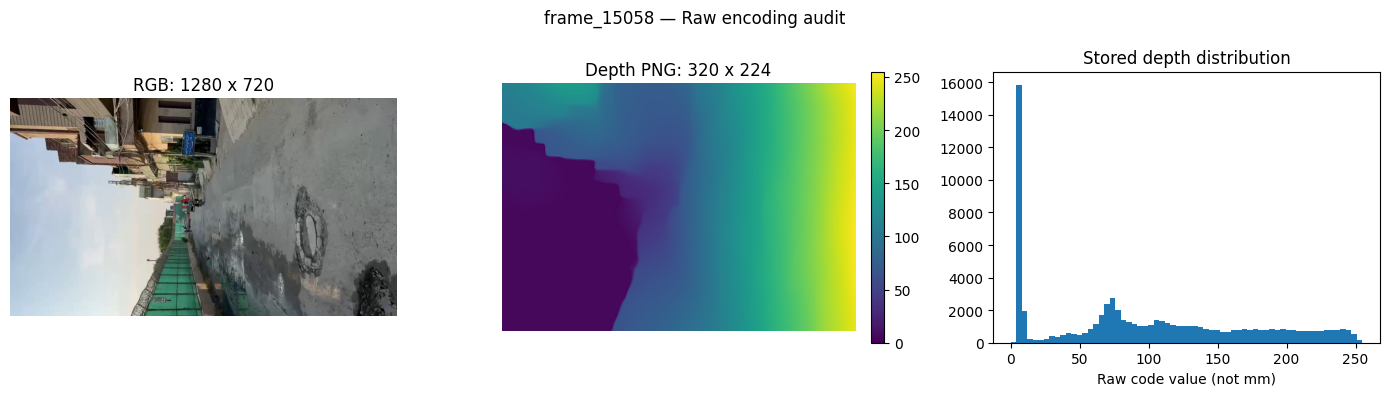


-------------------------------------------------------
FRAME: frame_12903
RGB shape: (720, 1280, 3)
Depth shape: (224, 320)
Depth dtype: uint8
Depth PNG mode: L
Dimensions match: False
Aspect ratio difference: 0.34921
Width ratio: 4.0
Height ratio: 3.2143
Unique depth values: 256
Raw depth range: 0.0 to 255.0


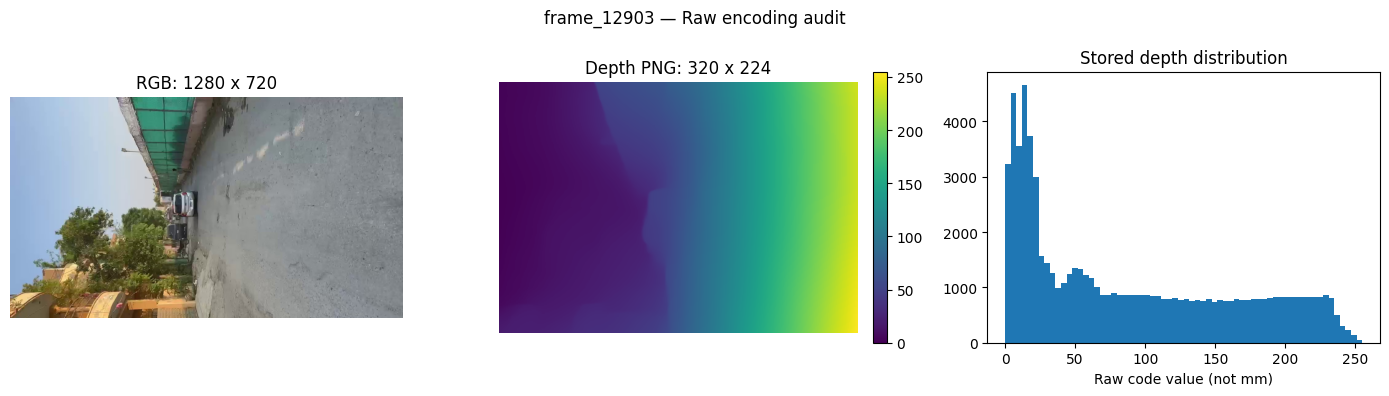


-------------------------------------------------------
FRAME: frame_04723
RGB shape: (1280, 720, 3)
Depth shape: (224, 320)
Depth dtype: uint8
Depth PNG mode: L
Dimensions match: False
Aspect ratio difference: 0.86607
Width ratio: 2.25
Height ratio: 5.7143
Unique depth values: 256
Raw depth range: 0.0 to 255.0


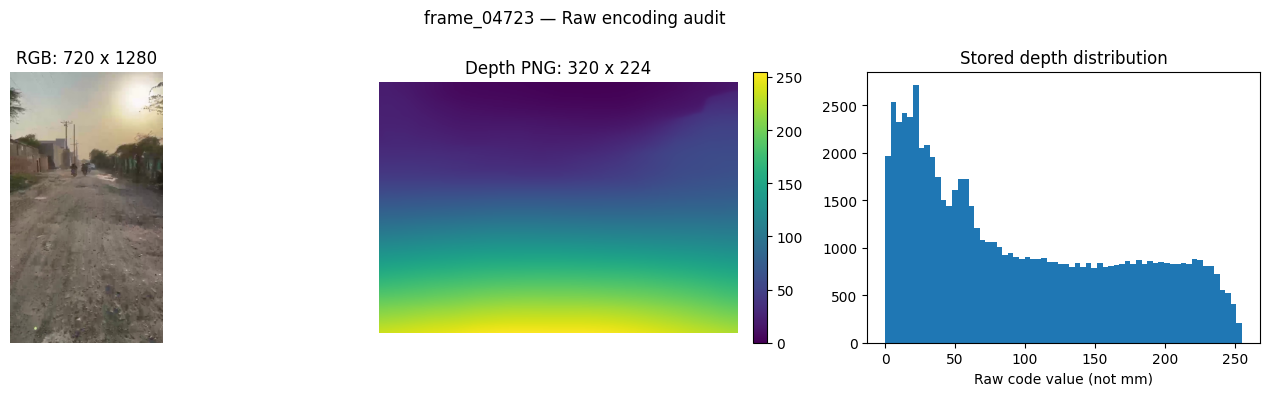


-------------------------------------------------------
FRAME: frame_00403
RGB shape: (1280, 720, 3)
Depth shape: (224, 320)
Depth dtype: uint8
Depth PNG mode: L
Dimensions match: False
Aspect ratio difference: 0.86607
Width ratio: 2.25
Height ratio: 5.7143
Unique depth values: 255
Raw depth range: 0.0 to 255.0


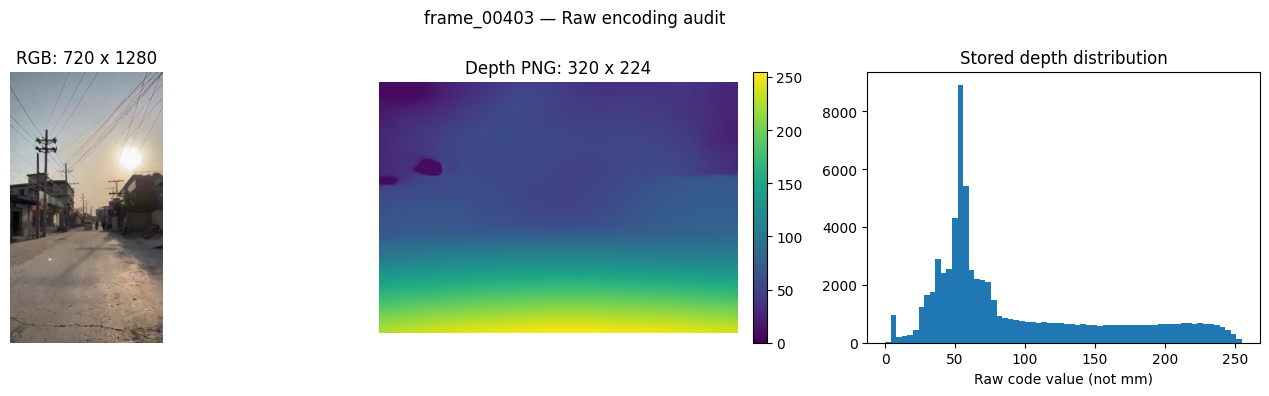


C3-01 SECTION 7 v1.1 — SUMMARY
Training examples inspected: 5
Dimension mismatches: 5
Depth dtypes: ['uint8']
Original images modified: NO
RGB-depth alignment verified: NO
Physical units certified: NO
Metric training authorized: NO
Reports saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-01_section07_v1_1_20261020T054342_282081Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-01 SECTION 7 (CORRECTED v1.1)
# BUTT RGB-LIDAR ENCODING AND RESOLUTION AUDIT
# TRAIN MANIFEST ONLY | READ-ONLY SOURCE DATA
# NO RESIZING | NO METRIC DEPTH ASSUMPTIONS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import hashlib
import json
import re

ROOT = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "butt_rgb_lidar"
)

AUDITS = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

MANIFEST = ROOT / "splits/pothole/train_files.txt"

assert ROOT.is_dir()
assert AUDITS.is_dir()
assert MANIFEST.is_file()

# ------------------------------------------------------------
# 1. READ EXPLICIT TRAINING PAIRS ONLY
# ------------------------------------------------------------

pairs = []

for line in MANIFEST.read_text(
    encoding="utf-8"
).splitlines():

    if not line.strip():
        continue

    items = line.split()

    if len(items) != 2:
        raise ValueError("Invalid train-manifest row")

    rgb_name, depth_name = items

    if not re.fullmatch(
        r"images/frame_\d+\.jpg", rgb_name
    ):
        raise ValueError("Unexpected RGB path")

    if not re.fullmatch(
        r"depth_maps/frame_\d+_depth\.png",
        depth_name
    ):
        raise ValueError("Unexpected depth path")

    rgb_id = Path(rgb_name).stem
    depth_id = Path(depth_name).stem.removesuffix(
        "_depth"
    )

    if rgb_id != depth_id:
        raise ValueError("Training-pair ID mismatch")

    pairs.append((rgb_name, depth_name))

assert len(pairs) > 0

# Select five deterministic TRAIN examples.
indices = np.linspace(
    0, len(pairs) - 1, 5, dtype=int
)

selected = [pairs[i] for i in indices]

print("=" * 65)
print("CRDL C3-01 — BUTT ENCODING AUDIT v1.1")
print("=" * 65)

print("Training manifest entries:", len(pairs))
print("Samples selected:", len(selected))
print("Validation and test manifests: NOT OPENED")

# ------------------------------------------------------------
# 2. CREATE VERSIONED OUTPUT DIRECTORY
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = AUDITS / f"C3-01_section07_v1_1_{stamp}"
OUT.mkdir(exist_ok=False)

records = []

# ------------------------------------------------------------
# 3. INSPECT FILES WITHOUT RESIZING
# ------------------------------------------------------------

for rgb_name, depth_name in selected:

    rgb_path = ROOT / rgb_name
    depth_path = ROOT / depth_name

    frame_id = Path(rgb_name).stem

    print("\n" + "-" * 55)
    print("FRAME:", frame_id)

    try:
        assert rgb_path.is_file()
        assert depth_path.is_file()
        assert not rgb_path.is_symlink()
        assert not depth_path.is_symlink()

        with Image.open(rgb_path) as im:
            rgb_mode = im.mode
            rgb = np.asarray(im.convert("RGB"))

        with Image.open(depth_path) as im:
            png_mode = im.mode
            png_metadata_keys = sorted(im.info.keys())
            depth = np.asarray(im)

        if depth.ndim != 2:
            raise ValueError(
                f"Expected 2D depth, found {depth.shape}"
            )

        rh, rw = rgb.shape[:2]
        dh, dw = depth.shape

        rgb_aspect = rw / rh
        depth_aspect = dw / dh

        dimension_match = (rh, rw) == (dh, dw)

        aspect_difference = abs(
            rgb_aspect - depth_aspect
        )

        # Pixel scale ratios are diagnostics only.
        # They DO NOT define valid image registration.
        scale_x = rw / dw
        scale_y = rh / dh

        numeric = depth.astype(np.float64)

        unique_values = int(
            np.unique(depth).size
        )

        record = {
            "frame_id": frame_id,
            "source_partition": "train",
            "status": "INSPECTED",
            "rgb_shape": list(rgb.shape),
            "depth_shape": list(depth.shape),
            "rgb_mode": rgb_mode,
            "depth_mode": png_mode,
            "depth_dtype": str(depth.dtype),
            "png_metadata_keys": png_metadata_keys,
            "dimensions_match": bool(dimension_match),
            "rgb_aspect": float(rgb_aspect),
            "depth_aspect": float(depth_aspect),
            "aspect_difference": float(
                aspect_difference
            ),
            "width_ratio_diagnostic": float(scale_x),
            "height_ratio_diagnostic": float(scale_y),
            "depth_unique_values": unique_values,
            "depth_min": float(numeric.min()),
            "depth_max": float(numeric.max()),
            "depth_median": float(
                np.median(numeric)
            ),
            "depth_p01": float(
                np.percentile(numeric, 1)
            ),
            "depth_p99": float(
                np.percentile(numeric, 99)
            ),
            "zero_fraction": float(
                np.mean(numeric == 0)
            ),
            "physical_units_verified": False,
            "rgb_depth_registration_verified": False,
        }

        records.append(record)

        print("RGB shape:", rgb.shape)
        print("Depth shape:", depth.shape)
        print("Depth dtype:", depth.dtype)
        print("Depth PNG mode:", png_mode)
        print("Dimensions match:", dimension_match)
        print(
            "Aspect ratio difference:",
            round(aspect_difference, 5)
        )
        print("Width ratio:", round(scale_x, 4))
        print("Height ratio:", round(scale_y, 4))
        print("Unique depth values:", unique_values)
        print(
            "Raw depth range:",
            record["depth_min"],
            "to",
            record["depth_max"]
        )

        # ----------------------------------------------------
        # 4. VISUALIZE NATIVE RGB AND DEPTH SEPARATELY
        # ----------------------------------------------------

        fig, axes = plt.subplots(
            1, 3, figsize=(14, 4)
        )

        axes[0].imshow(rgb)
        axes[0].set_title(
            f"RGB: {rw} x {rh}"
        )

        im = axes[1].imshow(
            depth, cmap="viridis"
        )
        axes[1].set_title(
            f"Depth PNG: {dw} x {dh}"
        )

        fig.colorbar(
            im, ax=axes[1],
            fraction=0.046, pad=0.04
        )

        axes[2].hist(
            numeric.ravel(), bins=64
        )
        axes[2].set_title(
            "Stored depth distribution"
        )
        axes[2].set_xlabel(
            "Raw code value (not mm)"
        )

        for ax in axes[:2]:
            ax.axis("off")

        fig.suptitle(
            f"{frame_id} — Raw encoding audit"
        )

        fig.tight_layout()

        figure_path = OUT / (
            f"{frame_id}_resolution_encoding.png"
        )

        fig.savefig(
            figure_path,
            dpi=130,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

    except Exception as exc:

        print("INSPECTION ERROR:", str(exc))

        records.append({
            "frame_id": frame_id,
            "source_partition": "train",
            "status": "INSPECTION_ERROR",
            "error": str(exc)
        })

# ------------------------------------------------------------
# 5. SAVE AUDIT REPORT
# ------------------------------------------------------------

successful = [
    r for r in records
    if r["status"] == "INSPECTED"
]

report = {
    "milestone": "C3-01",
    "section": 7,
    "version": "1.1",
    "dataset": "butt_rgb_lidar",
    "manifest_entries": len(pairs),
    "manifest_sha256": hashlib.sha256(
        MANIFEST.read_bytes()
    ).hexdigest(),
    "selected_train_samples": [
        r["frame_id"] for r in records
    ],
    "samples": records,
    "dimension_mismatches": sum(
        not r["dimensions_match"]
        for r in successful
    ),
    "no_image_resizing_performed": True,
    "alignment_verified": False,
    "physical_scale_verified": False,
    "metric_training_authorized": False,
    "external_triage_note": (
        "frame_25012 was inspected outside this "
        "cell before its partition was checked. "
        "It is not in the train manifest and is "
        "excluded from this development audit."
    ),
    "note": (
        "RGB/depth shape differences are retained. "
        "No assumptions about crop, resize, "
        "registration or physical scale are made."
    )
}

json_path = OUT / "butt_encoding_audit_v1_1.json"

json_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

csv_path = OUT / "butt_resolution_summary.csv"

pd.DataFrame(records).to_csv(
    csv_path, index=False
)

# ------------------------------------------------------------
# 6. CHECKSUM OUTPUT FILES
# ------------------------------------------------------------

checksum_lines = []

for path in sorted(OUT.iterdir()):

    if path.is_file():

        sha = hashlib.sha256(
            path.read_bytes()
        ).hexdigest()

        checksum_lines.append(
            f"{sha}  {path.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(checksum_lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 7. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-01 SECTION 7 v1.1 — SUMMARY")
print("=" * 65)

print("Training examples inspected:", len(successful))
print(
    "Dimension mismatches:",
    report["dimension_mismatches"]
)
print(
    "Depth dtypes:",
    sorted(set(
        r["depth_dtype"] for r in successful
    ))
)
print("Original images modified: NO")
print("RGB-depth alignment verified: NO")
print("Physical units certified: NO")
print("Metric training authorized: NO")
print("Reports saved:", OUT)

print("=" * 65)


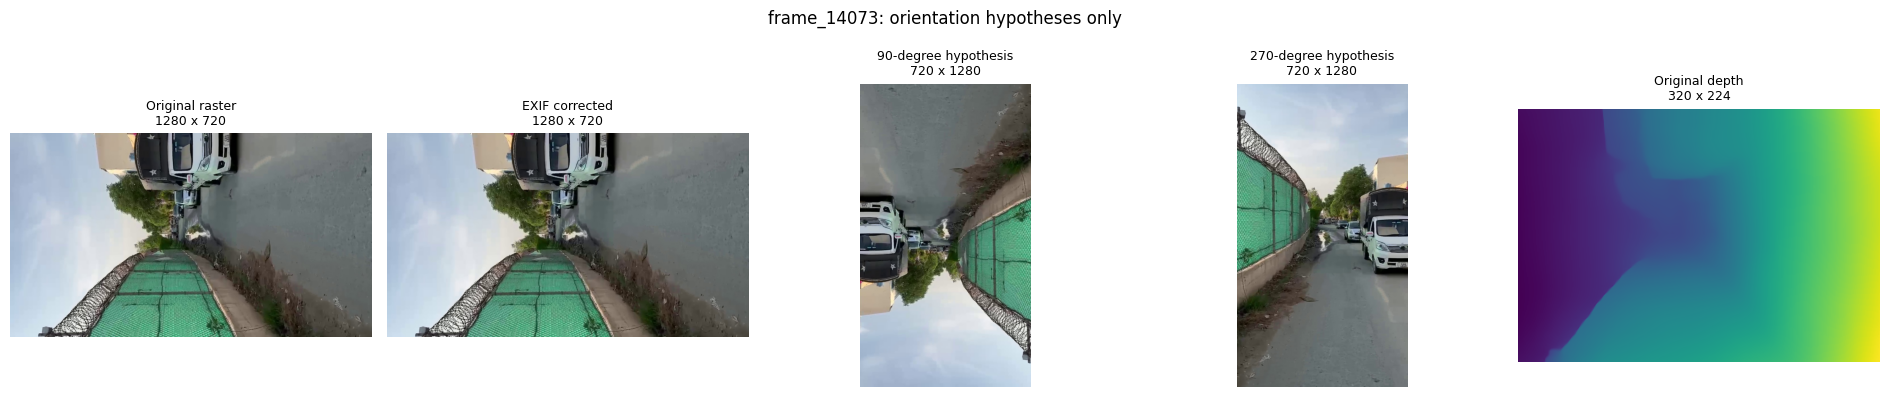


frame_14073
JPEG EXIF orientation: None
Native RGB: (720, 1280, 3)
EXIF-corrected RGB: (720, 1280, 3)
Depth: (224, 320)
Depth-to-RGB registration: NOT VERIFIED


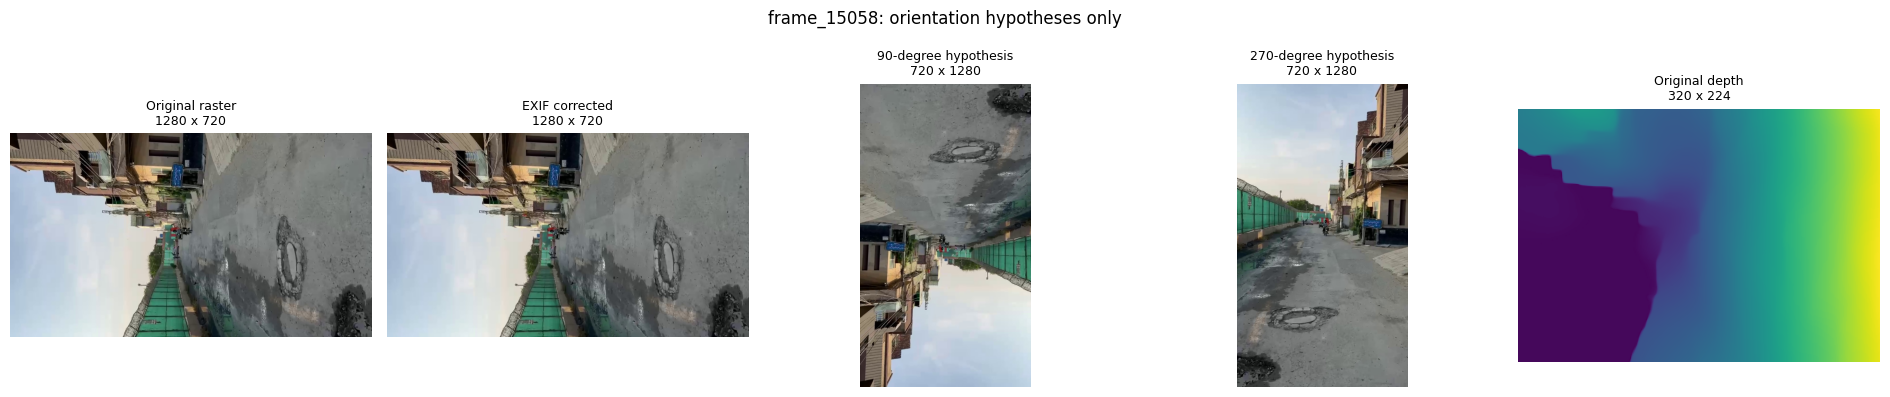


frame_15058
JPEG EXIF orientation: None
Native RGB: (720, 1280, 3)
EXIF-corrected RGB: (720, 1280, 3)
Depth: (224, 320)
Depth-to-RGB registration: NOT VERIFIED


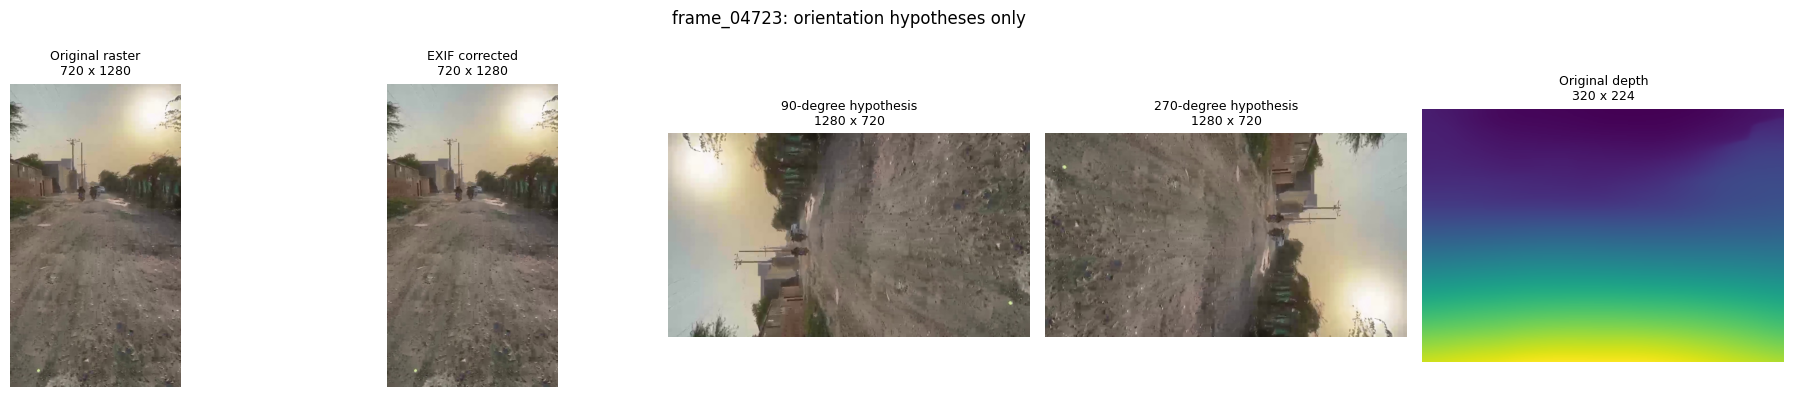


frame_04723
JPEG EXIF orientation: None
Native RGB: (1280, 720, 3)
EXIF-corrected RGB: (1280, 720, 3)
Depth: (224, 320)
Depth-to-RGB registration: NOT VERIFIED

CRDL C3-01 SECTION 8 — COMPLETE
Training samples examined: 3
Original source files modified: NO
EXIF information: RECORDED
RGB-depth registration: UNVERIFIED
Physical depth units: UNVERIFIED
Metric training authorized: NO
Saved reports: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-01_section08_20261020T055120_260258Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-01
# SECTION 8: BUTT IMAGE ORIENTATION & REGISTRATION AUDIT
# Version 1.0
# TRAIN-ONLY | READ-ONLY | NO METRIC UNIT ASSUMPTIONS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import hashlib
import json

DATA = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "butt_rgb_lidar"
)

AUDIT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

TRAIN_MANIFEST = (
    DATA / "splits/pothole/train_files.txt"
)

# Explicit development examples from Section 7.
SAMPLE_IDS = [
    "frame_14073",
    "frame_15058",
    "frame_04723"
]

assert TRAIN_MANIFEST.is_file()
assert AUDIT.is_dir()

# ------------------------------------------------------------
# 1. VERIFY TRAINING-PARTITION MEMBERSHIP
# ------------------------------------------------------------

train_pairs = {}

for line in TRAIN_MANIFEST.read_text(
    encoding="utf-8"
).splitlines():

    if not line.strip():
        continue

    fields = line.split()

    if len(fields) != 2:
        raise ValueError("Invalid training manifest")

    rgb_name, depth_name = fields

    train_pairs[Path(rgb_name).stem] = (
        rgb_name, depth_name
    )

for sample_id in SAMPLE_IDS:
    if sample_id not in train_pairs:
        raise RuntimeError(
            f"Not authorized for development: {sample_id}"
        )

# ------------------------------------------------------------
# 2. CREATE VERSIONED OUTPUT DIRECTORY
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = AUDIT / f"C3-01_section08_{stamp}"
OUT.mkdir(exist_ok=False)

records = []

# ------------------------------------------------------------
# 3. INSPECT NATIVE AND EXIF-CORRECTED ORIENTATIONS
# ------------------------------------------------------------

for sample_id in SAMPLE_IDS:

    rgb_rel, depth_rel = train_pairs[sample_id]

    rgb_path = DATA / rgb_rel
    depth_path = DATA / depth_rel

    assert rgb_path.is_file()
    assert depth_path.is_file()
    assert not rgb_path.is_symlink()
    assert not depth_path.is_symlink()

    with Image.open(rgb_path) as im:

        orientation_tag = im.getexif().get(274)

        # Preserve the original raster orientation.
        native = np.asarray(
            im.convert("RGB")
        )

        # Apply EXIF orientation only for comparison.
        corrected = np.asarray(
            ImageOps.exif_transpose(im).convert("RGB")
        )

    with Image.open(depth_path) as im:
        depth = np.asarray(im)
        depth_mode = im.mode
        depth_metadata_keys = sorted(
            im.info.keys()
        )

    if depth.ndim != 2:
        raise ValueError("Expected 2D depth map")

    # Visual orientation hypotheses only.
    # These are NOT registered RGB-depth pairs.
    rotated90 = np.rot90(corrected, k=1)
    rotated270 = np.rot90(corrected, k=3)

    def aspect(array):
        h, w = array.shape[:2]
        return float(w / h)

    depth_aspect = aspect(depth)

    views = {
        "native": native,
        "exif_corrected": corrected,
        "rot90_hypothesis": rotated90,
        "rot270_hypothesis": rotated270,
    }

    record = {
        "sample_id": sample_id,
        "partition": "train",
        "jpeg_exif_orientation": orientation_tag,
        "native_shape": list(native.shape),
        "exif_corrected_shape": list(corrected.shape),
        "depth_shape": list(depth.shape),
        "depth_mode": depth_mode,
        "depth_metadata_keys": depth_metadata_keys,
        "depth_aspect": depth_aspect,
        "candidate_views": {},
        "alignment_verified": False,
        "depth_unit_verified": False,
    }

    for name, array in views.items():

        candidate_aspect = aspect(array)

        record["candidate_views"][name] = {
            "shape": list(array.shape),
            "aspect_ratio": candidate_aspect,
            "aspect_difference_from_depth": abs(
                candidate_aspect - depth_aspect
            ),
        }

    # --------------------------------------------------------
    # 4. GENERATE SIDE-BY-SIDE ORIENTATION DIAGNOSTICS
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1, 5, figsize=(19, 4)
    )

    display_views = [
        ("Original raster", native),
        ("EXIF corrected", corrected),
        ("90-degree hypothesis", rotated90),
        ("270-degree hypothesis", rotated270),
    ]

    for i, (name, array) in enumerate(display_views):

        axes[i].imshow(array)

        h, w = array.shape[:2]

        axes[i].set_title(
            f"{name}\n{w} x {h}",
            fontsize=9
        )
        axes[i].axis("off")

    axes[4].imshow(
        depth, cmap="viridis"
    )

    dh, dw = depth.shape

    axes[4].set_title(
        f"Original depth\n{dw} x {dh}",
        fontsize=9
    )
    axes[4].axis("off")

    fig.suptitle(
        f"{sample_id}: orientation hypotheses only"
    )

    fig.tight_layout()

    figure_path = (
        OUT / f"{sample_id}_orientation_audit.png"
    )

    fig.savefig(
        figure_path,
        dpi=125,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    record["figure"] = figure_path.name
    records.append(record)

    print(f"\n{sample_id}")
    print("JPEG EXIF orientation:", orientation_tag)
    print("Native RGB:", native.shape)
    print("EXIF-corrected RGB:", corrected.shape)
    print("Depth:", depth.shape)
    print(
        "Depth-to-RGB registration:",
        "NOT VERIFIED"
    )

# ------------------------------------------------------------
# 5. SAVE SCIENTIFIC EVIDENCE
# ------------------------------------------------------------

report = {
    "milestone": "C3-01",
    "section": 8,
    "version": "1.0",
    "dataset": "butt_rgb_lidar",
    "source_partition": "train_only",
    "records": records,
    "rgb_depth_registration_verified": False,
    "metric_encoding_verified": False,
    "orientation_transform_certified": False,
    "metric_training_authorized": False,
    "source_files_modified": False,
    "methodology_note": (
        "JPEG orientation and visual rotations are "
        "diagnostic only. No candidate image was "
        "resized, geometrically registered or used "
        "to generate a metric training label."
    ),
}

json_path = OUT / "butt_orientation_audit.json"

json_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

summary_rows = []

for r in records:

    summary_rows.append({
        "sample": r["sample_id"],
        "exif_orientation": r["jpeg_exif_orientation"],
        "native_shape": str(r["native_shape"]),
        "corrected_shape": str(
            r["exif_corrected_shape"]
        ),
        "depth_shape": str(r["depth_shape"]),
        "registered": False,
    })

csv_path = OUT / "butt_orientation_summary.csv"

pd.DataFrame(summary_rows).to_csv(
    csv_path, index=False
)

# ------------------------------------------------------------
# 6. EXPORT CHECKSUMS
# ------------------------------------------------------------

hash_lines = []

for file in sorted(OUT.iterdir()):

    if file.is_file():

        digest = hashlib.sha256(
            file.read_bytes()
        ).hexdigest()

        hash_lines.append(
            f"{digest}  {file.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(hash_lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 7. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CRDL C3-01 SECTION 8 — COMPLETE")
print("=" * 65)

print("Training samples examined:", len(records))
print("Original source files modified: NO")
print("EXIF information: RECORDED")
print("RGB-depth registration: UNVERIFIED")
print("Physical depth units: UNVERIFIED")
print("Metric training authorized: NO")
print("Saved reports:", OUT)

print("=" * 65)


In [ ]:

# ============================================================
# CRDL C3-01 — SECTION 9
# POTHRGBD ORIGINAL DISTRIBUTION METADATA AUDIT
# Read-only | No extraction | No model training
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import zipfile
import json
import hashlib
import re

ROOT = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "pothrgbd/PData-main"
)

OUT_ROOT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

assert ROOT.is_dir()
assert OUT_ROOT.is_dir()

ARCHIVES = [
    "-depths.zip",
    "images.zip",
    "labels.zip",
]

METADATA_EXTENSIONS = {
    ".json", ".yaml", ".yml",
    ".xml", ".ini", ".csv",
    ".md", ".toml", ".bag",
    ".npz", ".mat", ".cfg"
}

KEYWORDS = re.compile(
    r"calibrat|intrinsic|extrinsic|"
    r"camera|sensor|scale|metadata|"
    r"realsense|config|depth_unit",
    re.IGNORECASE
)

def is_metadata_candidate(name):
    p = Path(name)

    return (
        p.suffix.lower() in METADATA_EXTENSIONS
        or (
            p.suffix.lower() == ".txt"
            and bool(KEYWORDS.search(p.name))
        )
    )

# ------------------------------------------------------------
# 1. INSPECT ORIGINAL ARCHIVE DIRECTORIES
# ------------------------------------------------------------

results = {}

for archive_name in ARCHIVES:

    path = ROOT / archive_name

    if not path.is_file() or path.is_symlink():
        results[archive_name] = {
            "status": "MISSING"
        }
        continue

    print("\nChecking:", archive_name)

    with zipfile.ZipFile(path) as z:
        entries = [
            item.filename
            for item in z.infolist()
            if not item.is_dir()
        ]

    candidates = [
        name for name in entries
        if is_metadata_candidate(name)
        and not any(
            x in name.lower().split("/")
            for x in (
                "test", "testing", "heldout",
                "holdout", "benchmark"
            )
        )
    ]

    results[archive_name] = {
        "status": "INDEX_READ",
        "file_entries": len(entries),
        "metadata_candidates": candidates[:100],
        "candidate_count": len(candidates),
        "contents_extracted": False,
    }

    print("File entries:", len(entries))
    print("Metadata candidates:", len(candidates))

    for name in candidates[:10]:
        print("  ", name)

# ------------------------------------------------------------
# 2. CHECK DISTRIBUTION-LEVEL DOCUMENTATION
# ------------------------------------------------------------

direct_candidates = []

for parent in [ROOT, ROOT.parent]:
    for p in parent.iterdir():
        if (
            p.is_file()
            and not p.is_symlink()
            and is_metadata_candidate(p.name)
        ):
            direct_candidates.append(
                str(p.relative_to(ROOT.parent))
            )

# ------------------------------------------------------------
# 3. RESEARCH DECISION
# ------------------------------------------------------------

total_candidates = sum(
    r.get("candidate_count", 0)
    for r in results.values()
)

status = (
    "METADATA_CANDIDATES_FOUND"
    if total_candidates or direct_candidates
    else "NO_DISTRIBUTION_METADATA_FOUND"
)

report = {
    "milestone": "C3-01",
    "section": 9,
    "dataset": "PothRGBD",
    "method": "distribution_metadata_index_audit",
    "archives": results,
    "direct_metadata_candidates": direct_candidates,
    "status": status,
    "source_sensor_reported": "RealSense D415",
    "depth_scale_m_per_raw_unit": None,
    "camera_intrinsics": None,
    "actual_scale_certified": False,
    "metric_training_authorized": False,
    "archive_payloads_read": False,
    "source_files_modified": False,
    "notes": (
        "This checks distributed archive filenames "
        "and root-level metadata only. "
        "Missing metadata in these locations does "
        "not prove calibration never existed."
    ),
}

# ------------------------------------------------------------
# 4. SAVE VERSIONED OUTPUT
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = OUT_ROOT / f"C3-01_section09_{stamp}"
OUT.mkdir(exist_ok=False)

path = OUT / "pothrgbd_metadata_evidence.json"

path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

digest = hashlib.sha256(
    path.read_bytes()
).hexdigest()

(OUT / "checksums.sha256").write_text(
    f"{digest}  {path.name}\n",
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("C3-01 SECTION 9 — RESULTS")
print("=" * 65)

print("Original archives checked:", len(ARCHIVES))
print("Metadata candidates:", total_candidates)
print("Direct metadata files:", len(direct_candidates))
print("Status:", status)
print("Physical scale verified: NO")
print("Metric training authorized: NO")
print("Report:", OUT)
print("=" * 65)



Checking: -depths.zip
File entries: 1000
Metadata candidates: 0

Checking: images.zip
File entries: 1000
Metadata candidates: 0

Checking: labels.zip
File entries: 1000
Metadata candidates: 0

C3-01 SECTION 9 — RESULTS
Original archives checked: 3
Metadata candidates: 0
Direct metadata files: 0
Status: NO_DISTRIBUTION_METADATA_FOUND
Physical scale verified: NO
Metric training authorized: NO
Report: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-01_section09_20261020T055714_260235Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-01
# SECTION 10: INDEPENDENT 3D GROUND-TRUTH DISCOVERY
# VERSION 1.0
# PUBLIC METADATA ONLY | NO SOURCE FILE DOWNLOADS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import requests
import hashlib
import json
import csv
import re

# ------------------------------------------------------------
# 1. RESEARCH SOURCE AND OUTPUT PATHS
# ------------------------------------------------------------

REPO = (
    "ruirangerfan/"
    "rethinking_road_reconstruction_pothole_detection"
)

API = (
    f"https://api.github.com/repos/{REPO}"
    "/git/trees/main?recursive=1"
)

AUDIT_ROOT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

assert AUDIT_ROOT.is_dir()

# ------------------------------------------------------------
# 2. RETRIEVE PUBLIC FILE-TREE METADATA
# ------------------------------------------------------------

print("=" * 65)
print("CRDL C3-01 — INDEPENDENT 3D GROUND TRUTH")
print("=" * 65)

print("Inspecting repository metadata...")
print("No data files will be downloaded.")

try:
    response = requests.get(
        API,
        headers={
            "Accept": "application/vnd.github+json",
            "User-Agent": "CRDL-Research-Audit"
        },
        timeout=40
    )
    response.raise_for_status()

    tree_data = response.json()

except requests.RequestException as exc:
    raise RuntimeError(
        "GitHub metadata request failed. "
        "Check internet access or API rate limits. "
        f"Details: {exc}"
    ) from exc

if tree_data.get("truncated", False):
    raise RuntimeError(
        "GitHub file tree is truncated; "
        "inventory cannot be considered complete."
    )

# ------------------------------------------------------------
# 3. IDENTIFY GROUND-TRUTH AND CALIBRATION FILES
# ------------------------------------------------------------

entries = []

def classify_file(relative):
    lower = relative.lower()

    if lower.startswith("gt/"):
        return "ground_truth_candidate"

    if "stereoparams" in lower or "calib" in lower:
        return "calibration_candidate"

    if "left" in lower:
        return "left_stereo_image"

    if "right" in lower:
        return "right_stereo_image"

    return "other"

for item in tree_data.get("tree", []):

    if item.get("type") != "blob":
        continue

    path = item["path"]

    match = re.match(
        r"^dataset/(model[123])/(.+)$",
        path
    )

    if not match:
        continue

    model_name, relative = match.groups()

    entries.append({
        "model": model_name,
        "path": path,
        "category": classify_file(relative),
        "extension": Path(path).suffix.lower(),
        "size_bytes": item.get("size"),
        "git_blob_sha": item.get("sha")
    })

if not entries:
    raise RuntimeError(
        "No expected dataset files found. "
        "Inspect repository structure before proceeding."
    )

# ------------------------------------------------------------
# 4. CREATE RESEARCH INVENTORY
# ------------------------------------------------------------

print("\nDATASET FILE INVENTORY")
print("-" * 65)

model_summaries = {}

for model_name in ("model1", "model2", "model3"):

    model_items = [
        x for x in entries
        if x["model"] == model_name
    ]

    categories = Counter(
        x["category"] for x in model_items
    )

    extensions = Counter(
        x["extension"] for x in model_items
    )

    model_summaries[model_name] = {
        "file_count": len(model_items),
        "categories": dict(categories),
        "extensions": dict(extensions),
        "source_files_opened": False
    }

    print(f"\n{model_name}: {len(model_items)} files")

    for category, count in categories.items():
        print(f"  {category}: {count}")

    print("  Extensions:", dict(extensions))

# ------------------------------------------------------------
# 5. RECORD SCIENTIFIC READINESS
# ------------------------------------------------------------

report = {
    "component": "CRDL_Component_3",
    "milestone": "C3-01",
    "section": 10,
    "version": "1.0",
    "repository": REPO,
    "source_tree_sha": tree_data.get("sha"),
    "source": (
        "https://github.com/" + REPO
    ),
    "models": model_summaries,
    "file_entries": entries,
    "independent_laser_ground_truth_reported": True,
    "published_stereo_reconstruction_rmse_mm": 2.23,
    "published_rmse_is_our_model_accuracy": False,
    "ground_truth_unit_verified": False,
    "ground_truth_alignment_verified": False,
    "overlap_with_existing_Fan_data_checked": False,
    "training_eligibility": "PENDING",
    "source_file_payloads_downloaded": False,
    "protected_evaluation_payloads_accessed": False,
    "metric_training_authorized": False,
    "note": (
        "Public Git repository metadata only. "
        "Ground-truth formats, physical units, "
        "pairing, overlap and calibration "
        "must be checked separately."
    )
}

# ------------------------------------------------------------
# 6. SAVE VERSIONED OUTPUTS
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = (
    AUDIT_ROOT / f"C3-01_section10_{stamp}"
)

OUT.mkdir(exist_ok=False)

json_path = OUT / "independent_3d_source_audit.json"

json_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

csv_path = OUT / "ground_truth_file_inventory.csv"

with csv_path.open(
    "w", newline="", encoding="utf-8"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=[
            "model", "path", "category",
            "extension", "size_bytes",
            "git_blob_sha"
        ]
    )

    writer.writeheader()
    writer.writerows(entries)

checksum_lines = []

for path in (json_path, csv_path):

    digest = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    checksum_lines.append(
        f"{digest}  {path.name}"
    )

(OUT / "checksums.sha256").write_text(
    "\n".join(checksum_lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 7. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-01 SECTION 10 — COMPLETED")
print("=" * 65)

print("Repository dataset files:", len(entries))
print("Models inventoried:", len(model_summaries))
print("Source data downloaded: NO")
print("Physical units verified: NO")
print("Metric training authorized: NO")
print("Reports saved:", OUT)

print("=" * 65)


CRDL C3-01 — INDEPENDENT 3D GROUND TRUTH
Inspecting repository metadata...
No data files will be downloaded.

DATASET FILE INVENTORY
-----------------------------------------------------------------

model1: 22 files
  ground_truth_candidate: 5
  left_stereo_image: 8
  right_stereo_image: 8
  calibration_candidate: 1
  Extensions: {'.ply': 5, '.png': 16, '.mat': 1}

model2: 33 files
  ground_truth_candidate: 4
  left_stereo_image: 14
  right_stereo_image: 14
  calibration_candidate: 1
  Extensions: {'.ply': 4, '.png': 28, '.mat': 1}

model3: 15 files
  ground_truth_candidate: 4
  left_stereo_image: 5
  right_stereo_image: 5
  calibration_candidate: 1
  Extensions: {'.ply': 4, '.png': 10, '.mat': 1}

C3-01 SECTION 10 — COMPLETED
Repository dataset files: 70
Models inventoried: 3
Source data downloaded: NO
Physical units verified: NO
Metric training authorized: NO
Reports saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-01_section10_20261020T060033_

In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-01 SECTION 11 v1.1
# PINNED GIT REVISION + LASER SCANNER PLY HEADERS
# NO FULL DATASET DOWNLOAD | NO MODEL TRAINING
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict, Counter
import requests
import hashlib
import json
import csv
import re

AUDIT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

SOURCE = AUDIT / (
    "C3-01_section10_20261020T060033_631516Z"
)

REPORT = SOURCE / "independent_3d_source_audit.json"
CHECKSUMS = SOURCE / "checksums.sha256"

REPO = (
    "ruirangerfan/"
    "rethinking_road_reconstruction_pothole_detection"
)

# ------------------------------------------------------------
# 1. VERIFY SECTION 10 EVIDENCE
# ------------------------------------------------------------

assert REPORT.is_file()
assert CHECKSUMS.is_file()

expected = {}

for line in CHECKSUMS.read_text().splitlines():
    if line.strip():
        sha, name = line.split(None, 1)
        expected[name.strip()] = sha

actual = hashlib.sha256(
    REPORT.read_bytes()
).hexdigest()

assert actual == expected[REPORT.name], (
    "Section 10 checksum mismatch"
)

previous = json.loads(
    REPORT.read_text(encoding="utf-8")
)

assert previous["section"] == 10

PINNED_TREE = previous["source_tree_sha"]
entries = previous["file_entries"]

print("Section 10 evidence integrity: PASS")
print("Recorded Git tree:", PINNED_TREE)

# ------------------------------------------------------------
# 2. LOAD THE EXACT PREVIOUS GIT TREE
# ------------------------------------------------------------

session = requests.Session()
session.headers.update({
    "User-Agent": "CRDL-Research-Audit",
    "Accept": "application/vnd.github+json"
})

TREE_URL = (
    f"https://api.github.com/repos/{REPO}"
    f"/git/trees/{PINNED_TREE}?recursive=1"
)

response = session.get(
    TREE_URL, timeout=40
)

if response.status_code != 200:
    raise RuntimeError(
        "The pinned Git tree could not be retrieved "
        f"(HTTP {response.status_code}). "
        "Do not substitute the latest main branch. "
        "The source inventory must be reconciled first."
    )

tree_data = response.json()

if tree_data.get("sha") != PINNED_TREE:
    raise RuntimeError(
        "Pinned Git tree identifier mismatch"
    )

if tree_data.get("truncated"):
    raise RuntimeError(
        "Pinned Git tree response is incomplete"
    )

pinned_files = {
    item["path"]: item
    for item in tree_data["tree"]
    if item.get("type") == "blob"
}

for item in entries:
    path = item["path"]

    if path not in pinned_files:
        raise RuntimeError(
            f"Missing from pinned revision: {path}"
        )

    if (
        pinned_files[path]["sha"]
        != item["git_blob_sha"]
    ):
        raise RuntimeError(
            f"Blob identifier mismatch: {path}"
        )

print("Pinned source-tree verification: PASS")
print("Verified inventory entries:", len(entries))

# ------------------------------------------------------------
# 3. CHECK STEREO FILE PAIRING AND DUPLICATES
# ------------------------------------------------------------

model_results = {}
hash_groups = defaultdict(list)

for item in entries:
    hash_groups[item["git_blob_sha"]].append(
        item["path"]
    )

duplicates = [
    paths
    for paths in hash_groups.values()
    if len(paths) > 1
]

for model in ("model1", "model2", "model3"):

    subset = [
        x for x in entries
        if x["model"] == model
    ]

    def numbered_files(category, prefix):
        result = set()

        for item in subset:
            if item["category"] != category:
                continue

            filename = Path(item["path"]).name

            match = re.fullmatch(
                rf"{prefix}(\d+)\.png",
                filename
            )

            if match is None:
                raise ValueError(
                    f"Unexpected filename: {filename}"
                )

            result.add(int(match.group(1)))

        return result

    left_ids = numbered_files(
        "left_stereo_image", "L"
    )
    right_ids = numbered_files(
        "right_stereo_image", "R"
    )

    gt_files = [
        x for x in subset
        if x["category"] == "ground_truth_candidate"
    ]

    model_results[model] = {
        "ply_files": len(gt_files),
        "stereo_pairs": len(left_ids & right_ids),
        "unpaired_left": sorted(
            left_ids - right_ids
        ),
        "unpaired_right": sorted(
            right_ids - left_ids
        ),
        "gt_to_stereo_correspondence_verified": False
    }

# ------------------------------------------------------------
# 4. STREAM PLY HEADERS BY IMMUTABLE GIT BLOB SHA
# ------------------------------------------------------------

MAX_HEADER_BYTES = 16384

def inspect_ply_blob(blob_sha):

    url = (
        f"https://api.github.com/repos/{REPO}"
        f"/git/blobs/{blob_sha}"
    )

    # Ask GitHub for the raw Git blob representation.
    # Stop reading as soon as the PLY header ends.
    with session.get(
        url,
        headers={
            "Accept": "application/vnd.github.raw+json"
        },
        stream=True,
        timeout=(15, 40)
    ) as response:

        response.raise_for_status()

        buffer = bytearray()
        header_end = None

        for chunk in response.iter_content(
            chunk_size=1024
        ):
            if not chunk:
                continue

            buffer.extend(chunk)

            if len(buffer) >= 3 and buffer[:3] != b"ply":
                raise ValueError(
                    "GitHub did not return raw PLY bytes"
                )

            for ending in (
                b"end_header\r\n",
                b"end_header\n"
            ):
                position = buffer.find(ending)

                if position >= 0:
                    header_end = (
                        position + len(ending)
                    )
                    break

            if header_end is not None:
                break

            if len(buffer) > MAX_HEADER_BYTES:
                raise ValueError(
                    "PLY header inspection limit exceeded"
                )

        if header_end is None:
            raise ValueError(
                "No complete PLY header received"
            )

        header = bytes(
            buffer[:header_end]
        ).decode("ascii", errors="replace")

    lines = header.splitlines()

    format_items = [
        x for x in lines
        if x.startswith("format ")
    ]

    vertex_items = [
        x for x in lines
        if x.startswith("element vertex ")
    ]

    properties = [
        x for x in lines
        if x.startswith("property ")
    ]

    comments = [
        x for x in lines
        if x.startswith("comment ")
    ]

    unit_evidence = [
        x for x in comments
        if re.search(
            r"\b(mm|millimeter|millimetre|"
            r"meters?|metres?|units?|scale)\b",
            x, re.IGNORECASE
        )
    ]

    return {
        "status": "HEADER_READ",
        "format": (
            format_items[0]
            if format_items else None
        ),
        "vertices": (
            int(vertex_items[0].split()[-1])
            if vertex_items else None
        ),
        "properties": properties[:30],
        "comments": comments[:30],
        "unit_evidence": unit_evidence,
        "physical_units_certified": False
    }

# ------------------------------------------------------------
# 5. INSPECT ONE SCANNER HEADER PER MODEL
# ------------------------------------------------------------

headers = {}

for model in ("model1", "model2", "model3"):

    candidates = sorted(
        [
            x for x in entries
            if x["model"] == model
            and x["category"] == "ground_truth_candidate"
        ],
        key=lambda x: x["path"]
    )

    if not candidates:
        raise RuntimeError(
            f"No scanner model found: {model}"
        )

    selected = candidates[0]

    print("\nInspecting:", selected["path"])

    try:
        info = inspect_ply_blob(
            selected["git_blob_sha"]
        )

        print("Format:", info["format"])
        print("Vertices:", info["vertices"])
        print("Unit evidence:", info["unit_evidence"])

    except Exception as exc:
        info = {
            "status": "HEADER_UNAVAILABLE",
            "error": (
                f"{type(exc).__name__}: {exc}"
            ),
            "physical_units_certified": False
        }

        print("Header unavailable:", info["error"])

    headers[model] = {
        "source_path": selected["path"],
        "git_blob_sha": selected["git_blob_sha"],
        **info
    }

# ------------------------------------------------------------
# 6. SAVE VERSIONED SCIENTIFIC RESULTS
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = AUDIT / f"C3-01_section11_v1_1_{stamp}"
OUT.mkdir(exist_ok=False)

report = {
    "milestone": "C3-01",
    "section": 11,
    "version": "1.1",
    "source_repository": REPO,
    "pinned_git_tree": PINNED_TREE,
    "source_tree_integrity": "PASS",
    "model_summary": model_results,
    "duplicate_blob_groups": duplicates,
    "ply_headers": headers,
    "full_scans_saved": False,
    "physical_units_verified": False,
    "stereo_gt_alignment_verified": False,
    "metric_training_authorized": False,
    "notes": (
        "Source inventory pinned to Section 10. "
        "PLY headers inspected through immutable "
        "blob identifiers when supported by GitHub."
    )
}

json_path = OUT / "laser_gt_readiness_v1_1.json"

json_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

csv_path = OUT / "laser_gt_header_summary.csv"

with csv_path.open(
    "w", newline="", encoding="utf-8"
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "model", "status", "vertices",
        "format", "unit_evidence"
    ])

    for model, info in headers.items():
        writer.writerow([
            model,
            info["status"],
            info.get("vertices"),
            info.get("format"),
            json.dumps(
                info.get("unit_evidence", [])
            )
        ])

hash_lines = []

for path in [json_path, csv_path]:
    hash_lines.append(
        hashlib.sha256(
            path.read_bytes()
        ).hexdigest()
        + "  " + path.name
    )

(OUT / "checksums.sha256").write_text(
    "\n".join(hash_lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 7. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-01 SECTION 11 v1.1 — RESULTS")
print("=" * 65)

print("Pinned Git tree: VERIFIED")
print("Source files inventoried:", len(entries))

print(
    "PLY headers read:",
    sum(
        x["status"] == "HEADER_READ"
        for x in headers.values()
    ),
    "/ 3"
)

print("Duplicate blob groups:", len(duplicates))
print("Full scanner files saved: NO")
print("Physical units certified: NO")
print("Metric training authorized: NO")
print("Report:", OUT)

print("=" * 65)


Section 10 evidence integrity: PASS
Recorded Git tree: d9378d0fcb5627c64514fb0ad69dbec03562090d
Pinned source-tree verification: PASS
Verified inventory entries: 70

Inspecting: dataset/model1/gt/model_1.ply
Format: format binary_little_endian 1.0
Vertices: 256969
Unit evidence: []

Inspecting: dataset/model2/gt/model_1.ply
Format: format binary_little_endian 1.0
Vertices: 261386
Unit evidence: []

Inspecting: dataset/model3/gt/model_1.ply
Format: format binary_little_endian 1.0
Vertices: 162677
Unit evidence: []

C3-01 SECTION 11 v1.1 — RESULTS
Pinned Git tree: VERIFIED
Source files inventoried: 70
PLY headers read: 3 / 3
Duplicate blob groups: 1
Full scanner files saved: NO
Physical units certified: NO
Metric training authorized: NO
Report: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-01_section11_v1_1_20261020T060935_521157Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-01
# SECTION 12: CALIBRATION EVIDENCE GATE & C3-02 HANDOFF
# Version 1.0
# NO SOURCE DATA READ | NO PHYSICAL LABEL GENERATION
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import csv

PROJECT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)

AUDIT = PROJECT / "02_dataset_audits"

assert AUDIT.is_dir()

# ------------------------------------------------------------
# 1. REGISTER COMPLETED CALIBRATION EXPERIMENTS
# ------------------------------------------------------------

RUNS = [
    "C3-01_section01_20261020T045938_052906Z",
    "C3-01_section02_20261020T050231_518844Z",
    "C3-01_section03_20261020T050850_399530Z",
    "C3-01_section04_20261020T051421_441716Z",
    "C3-01_section05_20261020T052734_099324Z",
    "C3-01_section06_20261020T053313_045228Z",
    "C3-01_section07_v1_1_20261020T054342_282081Z",
    "C3-01_section08_20261020T055120_260258Z",
    "C3-01_section09_20261020T055714_260235Z",
    "C3-01_section10_20261020T060033_631516Z",
    "C3-01_section11_v1_1_20261020T060935_521157Z",
]

def sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            digest.update(chunk)
    return digest.hexdigest()

# ------------------------------------------------------------
# 2. VERIFY ALL COMPLETED EXPERIMENT ARTIFACTS
# ------------------------------------------------------------

verified = []

for run in RUNS:

    directory = AUDIT / run
    checksums = directory / "checksums.sha256"

    if not directory.is_dir() or not checksums.is_file():
        raise FileNotFoundError(
            f"Missing calibration evidence: {run}"
        )

    count = 0

    for line in checksums.read_text(
        encoding="utf-8"
    ).splitlines():

        if not line.strip():
            continue

        expected, filename = line.split(None, 1)
        filename = filename.strip()

        if Path(filename).name != filename:
            raise ValueError("Unsafe checksum entry")

        file = directory / filename

        if not file.is_file():
            raise FileNotFoundError(file)

        if sha256(file) != expected:
            raise RuntimeError(
                f"Checksum failure: {file}"
            )

        count += 1

    if count == 0:
        raise RuntimeError(
            f"No recorded artifacts: {run}"
        )

    verified.append({
        "run": run,
        "artifacts_verified": count,
        "status": "PASS"
    })

print("=" * 65)
print("CRDL C3-01 — EVIDENCE INTEGRITY")
print("=" * 65)
print("Experiment runs verified:", len(verified))
print(
    "Total artifacts verified:",
    sum(x["artifacts_verified"] for x in verified)
)

# ------------------------------------------------------------
# 3. ESTABLISH THE CURRENT SCIENTIFIC READINESS GATE
# ------------------------------------------------------------

# These are evidence-based decisions from C3-01.
# They do not certify unverified physical scales.

DATASET_DECISIONS = [
    {
        "dataset": "Fan_stereo_dataset1_3",
        "role": "relative_3d_geometry_development",
        "geometry_available": True,
        "metric_scale_verified": False,
        "alignment_verified": True,
        "missing_evidence":
            "Dataset-specific physical scale and "
            "independent measurement validation"
    },
    {
        "dataset": "PothRGBD",
        "role": "sensor_depth_candidate",
        "geometry_available": True,
        "metric_scale_verified": False,
        "alignment_verified": False,
        "missing_evidence":
            "Capture depth scale, intrinsics, "
            "and RGB-depth registration"
    },
    {
        "dataset": "Pothole440",
        "role": "scanner_shape_candidate",
        "geometry_available": True,
        "metric_scale_verified": False,
        "alignment_verified": False,
        "missing_evidence":
            "Physical encoding of depth PNGs "
            "and geometric registration evidence"
    },
    {
        "dataset": "Butt_RGB_LiDAR",
        "role": "rgb_pretraining_candidate",
        "geometry_available": True,
        "metric_scale_verified": False,
        "alignment_verified": False,
        "missing_evidence":
            "Depth PNG scale, RGB-depth "
            "registration, orientation mapping"
    },
    {
        "dataset": "SHREC_2022",
        "role": "stereo_auxiliary_candidate",
        "geometry_available": True,
        "metric_scale_verified": False,
        "alignment_verified": False,
        "missing_evidence":
            "Stereo calibration and disparity encoding"
    },
    {
        "dataset": "Fan_laser_scanner_GT",
        "role": "quarantined_validation_candidate",
        "geometry_available": True,
        "metric_scale_verified": False,
        "alignment_verified": False,
        "missing_evidence":
            "PLY physical units, source correspondence, "
            "and overlap with protected evaluation data"
    },
    {
        "dataset": "Attain",
        "role": "visual_severity",
        "geometry_available": False,
        "metric_scale_verified": False,
        "alignment_verified": False,
        "missing_evidence":
            "Severity annotation semantics and pairing"
    },
    {
        "dataset": "SUT_Crack",
        "role": "crack_morphology",
        "geometry_available": False,
        "metric_scale_verified": False,
        "alignment_verified": False,
        "missing_evidence":
            "Image scale for physical crack metrology"
    },
]

# ------------------------------------------------------------
# 4. DEFINE THE REQUIRED RESEARCH DECISIONS
# ------------------------------------------------------------

GATES = {
    "dataset_inventory_complete": True,
    "exploratory_3d_feasibility_demonstrated": True,
    "source_calibration_provenance_investigated": True,
    "independent_metric_accuracy_demonstrated": False,
    "verified_metric_targets_available": False,
    "frozen_evaluation_authorized": False,
    "metric_CRDL_training_authorized": False,
    "relative_geometry_development_permitted": True,
    "relative_model_may_claim_physical_depth": False,
    "training_splits_frozen": False,
    "backend_model_release_authorized": False,
}

# ------------------------------------------------------------
# 5. CREATE VERSIONED HANDOFF REPORT
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = AUDIT / f"C3-01_section12_{stamp}"
OUT.mkdir(exist_ok=False)

report = {
    "component": "CRDL_Component_3",
    "milestone": "C3-01",
    "section": 12,
    "version": "1.0",
    "created_utc": stamp,
    "evidence_integrity": verified,
    "dataset_decisions": DATASET_DECISIONS,
    "scientific_gates": GATES,
    "protected_fan_dataset2_used": False,
    "historical_399_benchmark_used": False,
    "triage_exception":
        "One Butt frame outside the train manifest "
        "was previously inspected during debugging. "
        "It was excluded from development records.",
    "next_notebook":
        "C3-02_Geometry_Targets_v1",
    "next_stage":
        "Split provenance, relative geometry target "
        "design, validity masking, and controlled "
        "preliminary training preparation.",
    "metric_depth_claims_authorized": False,
}

json_path = OUT / "C3-01_calibration_gate.json"

json_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

csv_path = OUT / "dataset_evidence_matrix.csv"

with csv_path.open(
    "w", newline="", encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f, fieldnames=list(DATASET_DECISIONS[0])
    )

    writer.writeheader()
    writer.writerows(DATASET_DECISIONS)

# ------------------------------------------------------------
# 6. RECORD REQUIRED CALIBRATION REQUESTS
# ------------------------------------------------------------

requests_text = """# CRDL — Outstanding Physical Calibration Evidence

## Fan stereo
Request original camera calibration, XYZ coordinate units,
and validation evidence for dataset1/dataset3.

## PothRGBD
Request RealSense depth_scale, camera intrinsics,
RGB-depth alignment details, and original acquisition settings.

## Pothole440
Request the conversion from depth PNG values into
scanner-derived physical distances and associated units.

## Butt RGB-LiDAR
Request 8-bit depth PNG encoding formula, physical depth
scale, RGB-depth registration and image orientation rules.

## SHREC
Request OAK-D calibration, disparity encoding and
synchronized RGB/disparity interpretation.

## Fan laser-scanner source
Request original scanner units, scan-to-stereo correspondence,
and details needed to rule out evaluation overlap.

No unverified source is approved for metric target creation.
"""

request_path = OUT / "calibration_evidence_requests.md"

request_path.write_text(
    requests_text, encoding="utf-8"
)

# ------------------------------------------------------------
# 7. GENERATE CHECKSUMS
# ------------------------------------------------------------

lines = []

for file in [json_path, csv_path, request_path]:
    lines.append(
        f"{sha256(file)}  {file.name}"
    )

(OUT / "checksums.sha256").write_text(
    "\n".join(lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 8. FINAL GATE DECISION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-01 SECTION 12 — CALIBRATION GATE")
print("=" * 65)

print("Evidence integrity: PASS")
print("Exploratory geometry development: PERMITTED")
print("Physical metric supervision: NOT VERIFIED")
print("Metric CRDL training: NOT AUTHORIZED")
print("Frozen evaluation data: PROTECTED")
print("Next milestone: C3-02 Geometry Targets")
print("Saved reports:", OUT)

print("=" * 65)


CRDL C3-01 — EVIDENCE INTEGRITY
Experiment runs verified: 11
Total artifacts verified: 35

C3-01 SECTION 12 — CALIBRATION GATE
Evidence integrity: PASS
Exploratory geometry development: PERMITTED
Physical metric supervision: NOT VERIFIED
Metric CRDL training: NOT AUTHORIZED
Frozen evaluation data: PROTECTED
Next milestone: C3-02 Geometry Targets
Saved reports: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-01_section12_20261020T061406_040129Z
